# Part 1 (ii): Time series: House Property Sales
**CMPE 255: EDA, data preparation and AutoML on a time series**

| | |
|---|---|
| **Dataset** | [House Property Sales Time Series (Kaggle)](https://www.kaggle.com/datasets/htagholdings/property-sales): `raw_sales.csv` has 29,580 individual residential sales (date, postcode, price, house/unit, bedrooms) in the Canberra/ACT region, 2007 to 2019. `ma_lga_12345.csv` is the publisher's quarterly moving-average median price by property type and bedrooms. |
| **Why this dataset** | Raw transactions arrive at **irregular dates** and must be turned into a regular series. Early years are sparse, some weeks have no sales, prices range from $56k to $8M, and some records are inconsistent (e.g. houses with 0 bedrooms). So cleaning, imputation and anomaly handling are all genuinely needed. |
| **Forecasting task** | Predict next week's **median house sale price** from information available up to the previous week |
| **AutoML** | AutoViML (regression) + AutoViz |

### Pipeline
```
Load → Overview → Data-quality audit → Transaction-level EDA → Auto-EDA (AutoViz)
     → Fix the series window and the chronological train/test boundary
     → Transaction cleaning (types, bedroom imputation, postcode-aware price anomalies learned on train years)
     → Aggregate to a weekly series → Imputation of missing weeks (causal methods only)
     → Time-series EDA (trend, seasonality, stationarity, autocorrelation)
     → Series-level anomaly removal (train only) → Clustering of postcodes by price trajectory
     → Lag/rolling/calendar feature engineering → Feature selection
     → AutoViML models + naive baselines → Holdout evaluation
     → Walk-forward evaluation (2013–2019) with significance tests → Conclusions
```
**Leakage rules for time series:** the split is **chronological** (never random). Every feature at week *t* uses only data up to week *t−1*. Anything learned from data (imputation choice, anomaly thresholds, clusters, feature selection) is learned on the training period only.

### How this notebook was built
> ✍️ *TODO (you): describe how you used a coding agent and what you reviewed or changed yourself.*

## 0. Setup
Same pinned environment as the tabular notebook (`part1/requirements.txt`). On Colab the next cell installs it and restarts the runtime once. Afterwards choose *Runtime → Run all*.

In [1]:
import os, sys

IN_COLAB = "google.colab" in sys.modules


def _env_ready():
    try:
        import importlib.metadata as md
        return (md.version("autoviml") == "0.2.2"
                and md.version("scikit-learn") == "1.3.2"
                and md.version("numpy").startswith("1."))
    except Exception:
        return False


if IN_COLAB and not _env_ready():
    %pip install -q autoviml==0.2.2 autoviz==0.1.905 scikit-learn==1.3.2 imbalanced-learn==0.12.4 "numpy<2" scipy==1.11.4 "pandas<2.3" "setuptools<81"
    print("Installed pinned packages -> restarting runtime. Afterwards: Runtime -> Run all.")
    os.kill(os.getpid(), 9)

In [2]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import IsolationForest
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, mean_absolute_error, mean_squared_error


pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (12, 4.5)
dollars = mtick.FuncFormatter(lambda x, _: f"${x / 1e3:,.0f}k")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# ---- run configuration ----
RUN_AUTOVIZ = True
MIN_SALES_PER_WEEK = 10   # weekly medians from fewer sales than this are too noisy -> treated as missing
TEST_FRACTION = 0.2       # last 20% of weeks are the test period
TARGET = "y_rel"          # defined in section 11

In [3]:
REPO_RAW = "https://raw.githubusercontent.com/anita-agasaveeran/CMPE255_Exploratory_Data_Analysis/main/data/"


def load_csv(name, **kw):
    """Load from the repo's data/ folder when run locally, otherwise from GitHub (e.g. on Colab)."""
    for base in [Path("../../data"), Path("../data"), Path("data"), Path("/content/data")]:
        if (base / name).exists():
            print(f"Loading local file {base / name}")
            return pd.read_csv(base / name, **kw)
    print(f"Loading {REPO_RAW + name}")
    return pd.read_csv(REPO_RAW + name, **kw)


raw = load_csv("property_sales/raw_sales.csv", parse_dates=["datesold"])
ma = load_csv("property_sales/ma_lga_12345.csv")
ma["saledate"] = pd.to_datetime(ma["saledate"], format="%d/%m/%Y")
print("raw_sales:", raw.shape, "| ma_lga:", ma.shape)
raw.head()

Loading local file ../../data/property_sales/raw_sales.csv
Loading local file ../../data/property_sales/ma_lga_12345.csv
raw_sales: (29580, 5) | ma_lga: (347, 4)


,datesold,postcode,price,propertyType,bedrooms
0,2007-02-07,2607,525000,house,4
1,2007-02-27,2906,290000,house,3
2,2007-03-07,2905,328000,house,3
3,2007-03-09,2905,380000,house,4
4,2007-03-21,2906,310000,house,3


## 1. Data overview

In [4]:
raw.info()
display(raw.describe(include="all").T)
print("Date range:", raw["datesold"].min().date(), "→", raw["datesold"].max().date())
print("Postcodes:", raw["postcode"].nunique())
display(pd.crosstab(raw["propertyType"], raw["bedrooms"], margins=True))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29580 entries, 0 to 29579
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   datesold      29580 non-null  datetime64[ns]
 1   postcode      29580 non-null  int64         
 2   price         29580 non-null  int64         
 3   propertyType  29580 non-null  object        
 4   bedrooms      29580 non-null  int64         
dtypes: datetime64[ns](1), int64(3), object(1)
memory usage: 1.1+ MB


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
datesold,29580,NaN,NaN,NaN,2015-02-21 07:35:42.474645248,2007-02-07 00:00:00,2013-02-05 00:00:00,2015-09-30 00:00:00,2017-07-26 00:00:00,2019-07-27 00:00:00,NaN
postcode,29580.0,NaN,NaN,NaN,2730.24973,2600.0,2607.0,2615.0,2905.0,2914.0,146.717292
price,29580.0,NaN,NaN,NaN,609736.262204,56500.0,440000.0,550000.0,705000.0,8000000.0,281707.905374
propertyType,29580,2,house,24552,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bedrooms,29580.0,NaN,NaN,NaN,3.250169,0.0,3.0,3.0,4.0,5.0,0.951275


Date range: 2007-02-07 → 2019-07-27
Postcodes: 27


bedrooms,0,1,2,3,4,5,All
propertyType,,,,,,,
house,19,95,806,11281,10404,1947,24552
unit,11,1532,2792,652,38,3,5028
All,30,1627,3598,11933,10442,1950,29580


In [5]:
ma.head()

,saledate,MA,type,bedrooms
0,2007-09-30,441854,house,2
1,2007-12-31,441854,house,2
2,2008-03-31,441854,house,2
3,2008-06-30,441854,house,2
4,2008-09-30,451583,house,2


## 2. Data-quality audit

In [6]:
checks = {
    "Missing values (all columns)": raw.isna().sum().sum(),
    "Exact duplicate rows": raw.duplicated().sum(),
    "Same date + postcode + price + type (possible double entry)": raw.duplicated(["datesold", "postcode", "price", "propertyType"]).sum(),
    "Houses with 0 bedrooms (implausible)": ((raw["propertyType"] == "house") & (raw["bedrooms"] == 0)).sum(),
    "Units with 0 bedrooms (studios, plausible)": ((raw["propertyType"] == "unit") & (raw["bedrooms"] == 0)).sum(),
    "Sales recorded on a Sunday": (raw["datesold"].dt.dayofweek == 6).sum(),
    "Price < $100k": (raw["price"] < 100_000).sum(),
    "Price > $3M": (raw["price"] > 3_000_000).sum(),
    "Postcodes with < 30 sales in 12 years": (raw["postcode"].value_counts() < 30).sum(),
}
pd.Series(checks, name="count").to_frame()

,count
Missing values (all columns),0
Exact duplicate rows,0
Same date + postcode + price + type (possible double entry),26
Houses with 0 bedrooms (implausible),19
"Units with 0 bedrooms (studios, plausible)",11
Sales recorded on a Sunday,216
Price < $100k,11
Price > $3M,20
Postcodes with < 30 sales in 12 years,4


### 2.1 Coverage over time
A forecasting series needs enough observations in every period. The data is very sparse at the start, and 2019 is only partial.

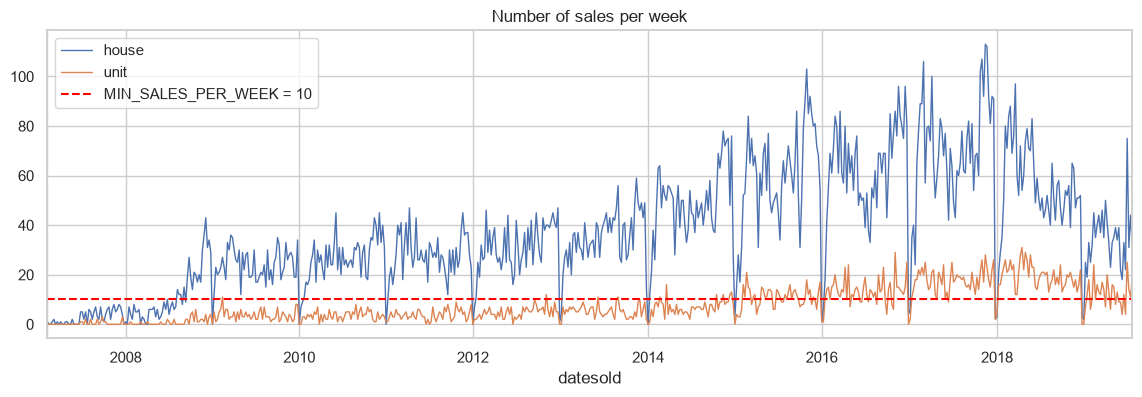

datesold,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019
sales per year,147,639,1426,1555,1633,1858,2119,2863,3648,3908,4541,3858,1385


In [7]:
wk_counts = raw.set_index("datesold").groupby("propertyType").resample("W-SUN").size().unstack(0).fillna(0)
ax = wk_counts.plot(figsize=(14, 4), lw=1)
ax.axhline(MIN_SALES_PER_WEEK, color="red", ls="--", label=f"MIN_SALES_PER_WEEK = {MIN_SALES_PER_WEEK}")
ax.set_title("Number of sales per week")
ax.legend()
plt.show()
display(raw.groupby(raw["datesold"].dt.year).size().rename("sales per year").to_frame().T)

> ✍️ **Your observations (audit):** what is wrong or risky in the raw data, and which issues matter for building a weekly series?

## 3. Exploratory data analysis (transaction level)
### 3.1 Price distribution

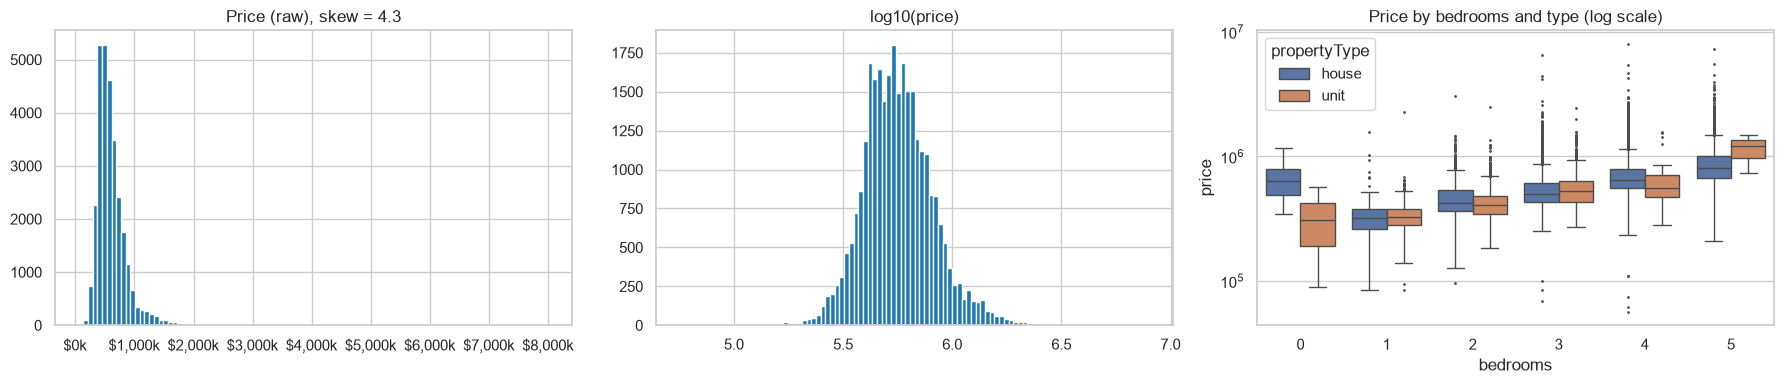

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].hist(raw["price"], bins=100, color="tab:blue")
axes[0].set_title(f"Price (raw), skew = {raw['price'].skew():.1f}")
axes[0].xaxis.set_major_formatter(dollars)
axes[1].hist(np.log10(raw["price"]), bins=100, color="tab:blue")
axes[1].set_title("log10(price)")
sns.boxplot(data=raw, x="bedrooms", y="price", hue="propertyType", ax=axes[2], fliersize=1)
axes[2].set_yscale("log")
axes[2].set_title("Price by bedrooms and type (log scale)")
plt.tight_layout()
plt.show()

### 3.2 Price and volume over time

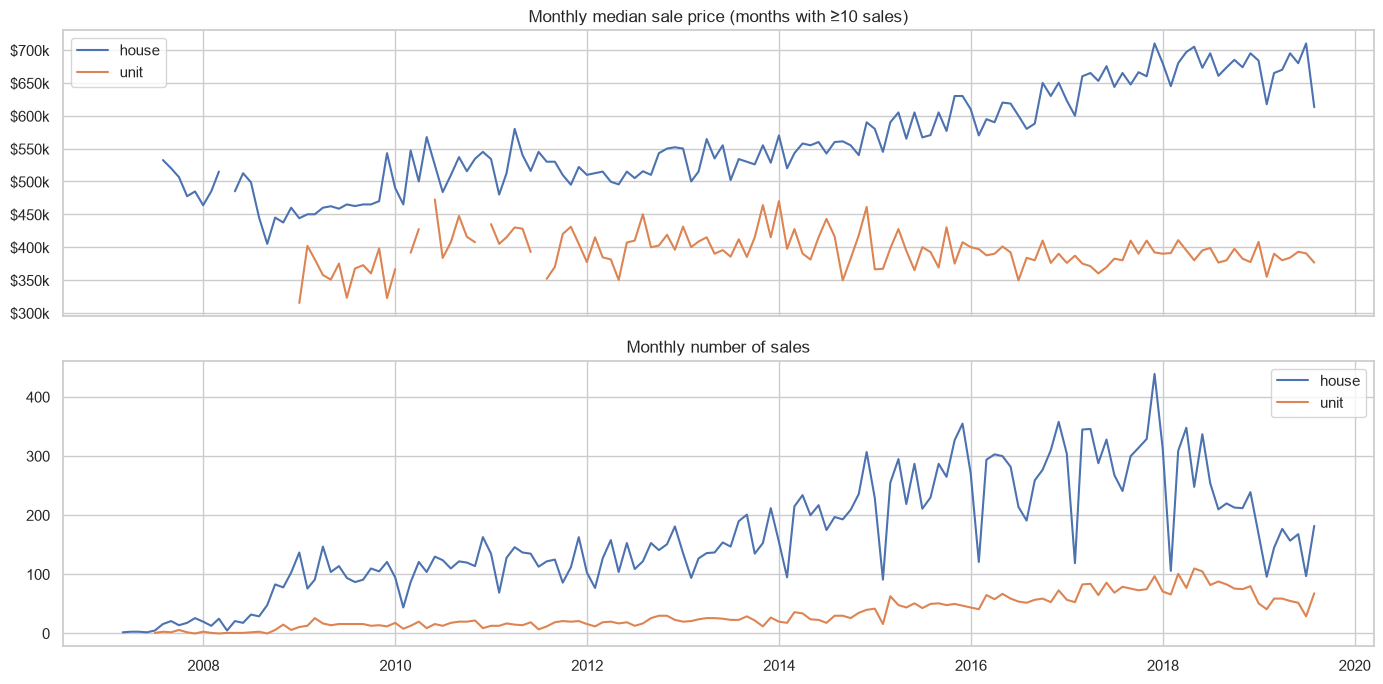

In [9]:
monthly = raw.set_index("datesold").groupby("propertyType").resample("ME")["price"].agg(["median", "size"])
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
for t in ["house", "unit"]:
    m = monthly.loc[t]
    axes[0].plot(m.index, m["median"].where(m["size"] >= 10), label=t)
    axes[1].plot(m.index, m["size"], label=t)
axes[0].yaxis.set_major_formatter(dollars)
axes[0].set_title("Monthly median sale price (months with ≥10 sales)")
axes[0].legend()
axes[1].set_title("Monthly number of sales")
axes[1].legend()
plt.tight_layout()
plt.show()

### 3.3 Seasonality in when sales happen

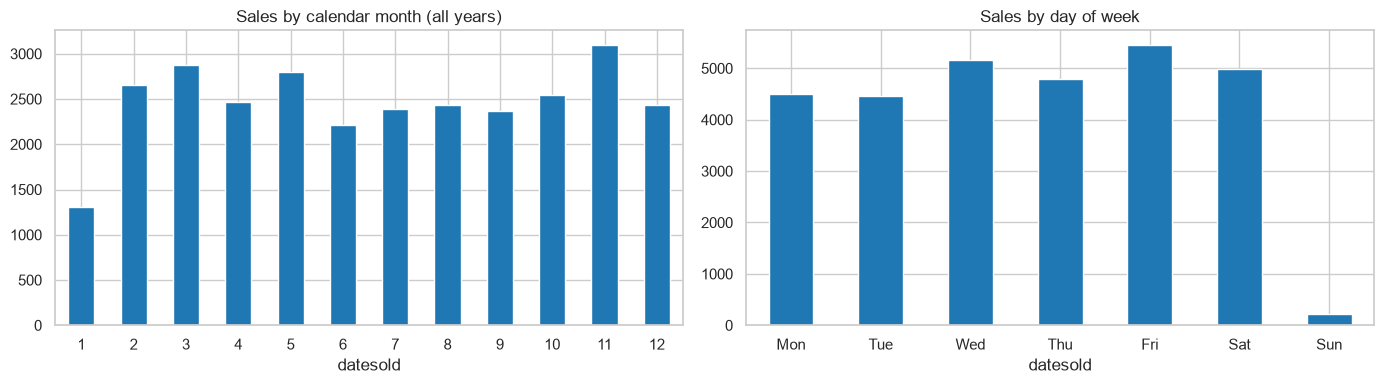

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
raw.groupby(raw["datesold"].dt.month).size().plot.bar(ax=axes[0], color="tab:blue", rot=0)
axes[0].set_title("Sales by calendar month (all years)")
raw.groupby(raw["datesold"].dt.dayofweek).size().rename(index=dict(enumerate("Mon Tue Wed Thu Fri Sat Sun".split()))) \
    .plot.bar(ax=axes[1], color="tab:blue", rot=0)
axes[1].set_title("Sales by day of week")
plt.tight_layout()
plt.show()

### 3.4 Geography: postcodes

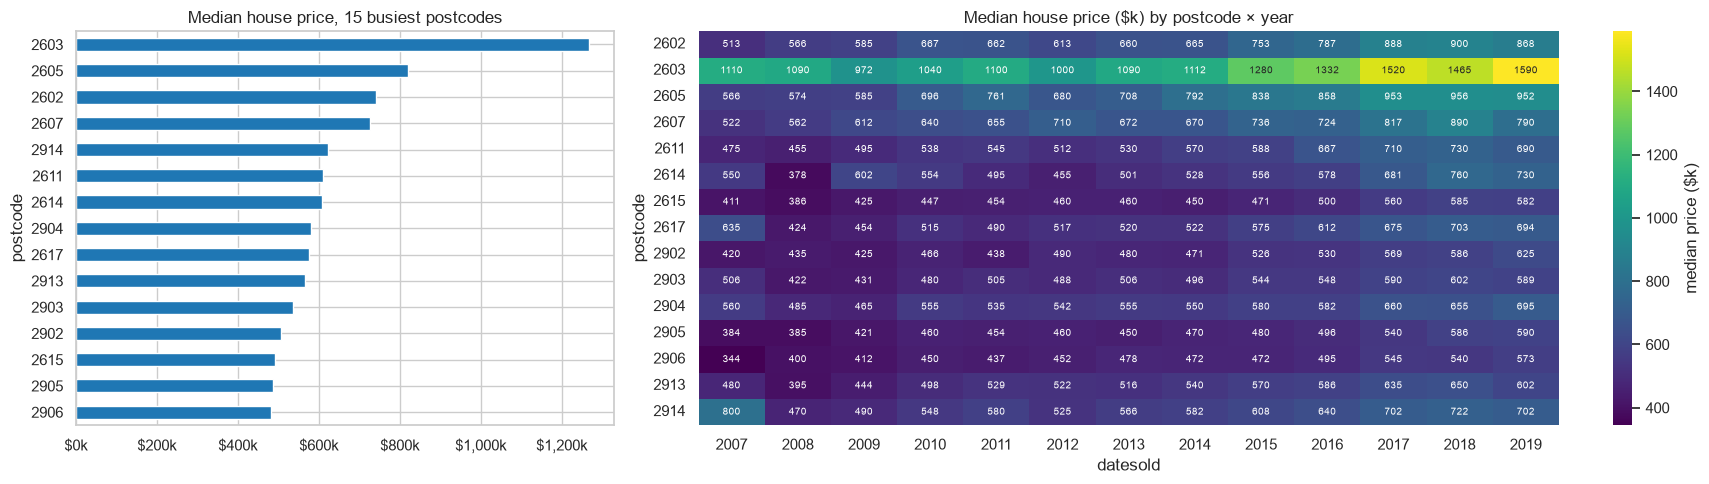

In [11]:
pc = raw[raw["propertyType"] == "house"].groupby("postcode")["price"].agg(["size", "median"]).sort_values("size", ascending=False)
top_pc = pc.head(15).index
heat = raw[(raw["propertyType"] == "house") & raw["postcode"].isin(top_pc)] \
    .pivot_table(index="postcode", columns=raw["datesold"].dt.year, values="price", aggfunc="median")
fig, axes = plt.subplots(1, 2, figsize=(18, 5), gridspec_kw={"width_ratios": [1, 2]})
pc.head(15)["median"].sort_values().plot.barh(ax=axes[0], color="tab:blue")
axes[0].xaxis.set_major_formatter(dollars)
axes[0].set_title("Median house price, 15 busiest postcodes")
sns.heatmap(heat / 1e3, cmap="viridis", ax=axes[1], annot=True, fmt=".0f", annot_kws={"size": 7},
            cbar_kws={"label": "median price ($k)"})
axes[1].set_title("Median house price ($k) by postcode × year")
plt.tight_layout()
plt.show()

### 3.5 The publisher's moving-average series (`ma_lga_12345.csv`)

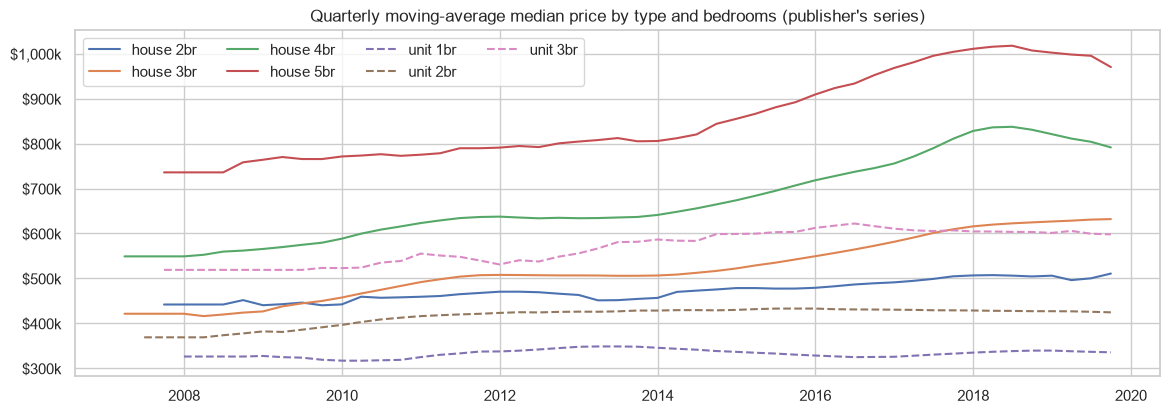

In [12]:
fig, ax = plt.subplots(figsize=(14, 4.5))
for (t, b), g in ma.groupby(["type", "bedrooms"]):
    ax.plot(g["saledate"], g["MA"], label=f"{t} {b}br", ls="-" if t == "house" else "--")
ax.yaxis.set_major_formatter(dollars)
ax.set_title("Quarterly moving-average median price by type and bedrooms (publisher's series)")
ax.legend(ncol=4)
plt.show()

> ✍️ **Your observations (EDA):** describe the long-run trend, house vs unit gap, seasonality of sales volume, and how much prices differ by postcode.

## 4. Automated EDA with AutoViz

Imported v0.1.905. Please call AutoViz in this sequence:
    AV = AutoViz_Class()
    %matplotlib inline
    dfte = AV.AutoViz(filename, sep=',', depVar='', dfte=None, header=0, verbose=1, lowess=False,
               chart_format='svg',max_rows_analyzed=150000,max_cols_analyzed=30, save_plot_dir=None)
Shape of your Data Set loaded: (29580, 6)
#######################################################################################
######################## C L A S S I F Y I N G  V A R I A B L E S  ####################
#######################################################################################
Classifying variables in data set...
    Number of Numeric Columns =  0
    Number of Integer-Categorical Columns =  2
    Number of String-Categorical Columns =  1
    Number of Factor-Categorical Columns =  0
    Number of String-Boolean Columns =  1
    Number of Numeric-Boolean Columns =  0
    Number of Discrete String Columns =  0
    Number of NLP String Columns =  0
    Number of

,Data Type,Missing Values%,Unique Values%,Minimum Value,Maximum Value,DQ Issue
postcode,object,0.000000,0,,,"7 rare categories: ['2601', '2911', '2900', '2620', '2616', '2609', '2618']. Group them into a single category or drop the categories."
propertyType,object,0.000000,0,,,No issue
bedrooms,int64,0.000000,0,0.000000,5.000000,Column has 1636 outliers greater than upper bound (5.50) or lower than lower bound(1.50). Cap them or remove them.
year,int32,0.000000,0,2007.000000,2019.000000,Possible date-time colum: transform before modeling step.
month,int32,0.000000,0,1.000000,12.000000,No issue
price,int64,0.000000,8,56500.000000,8000000.000000,Target column


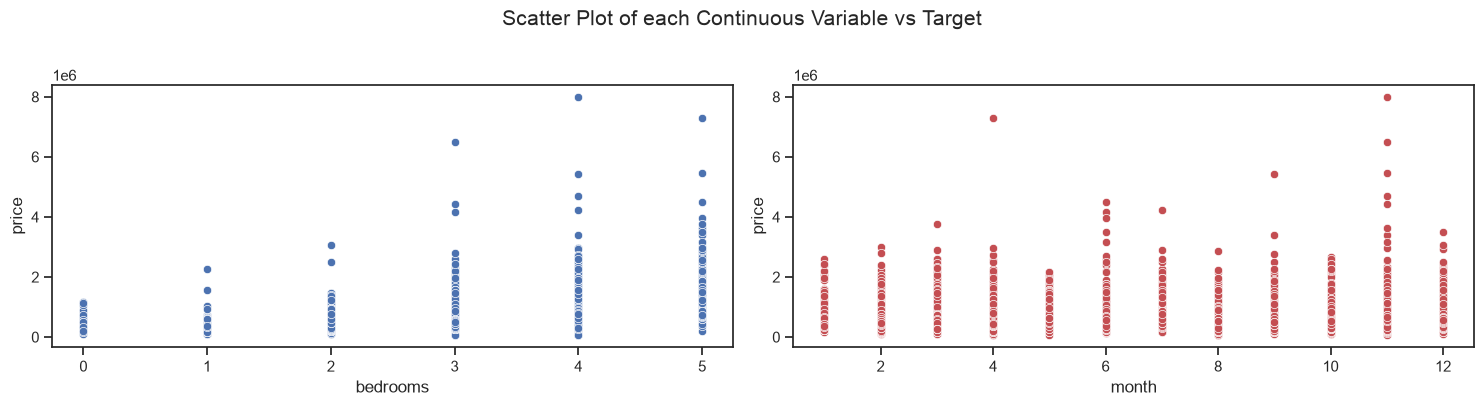

Number of All Scatter Plots = 3


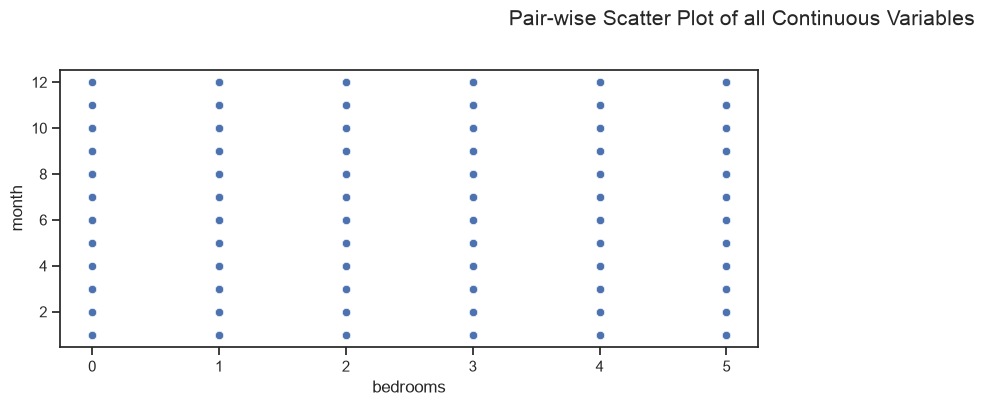

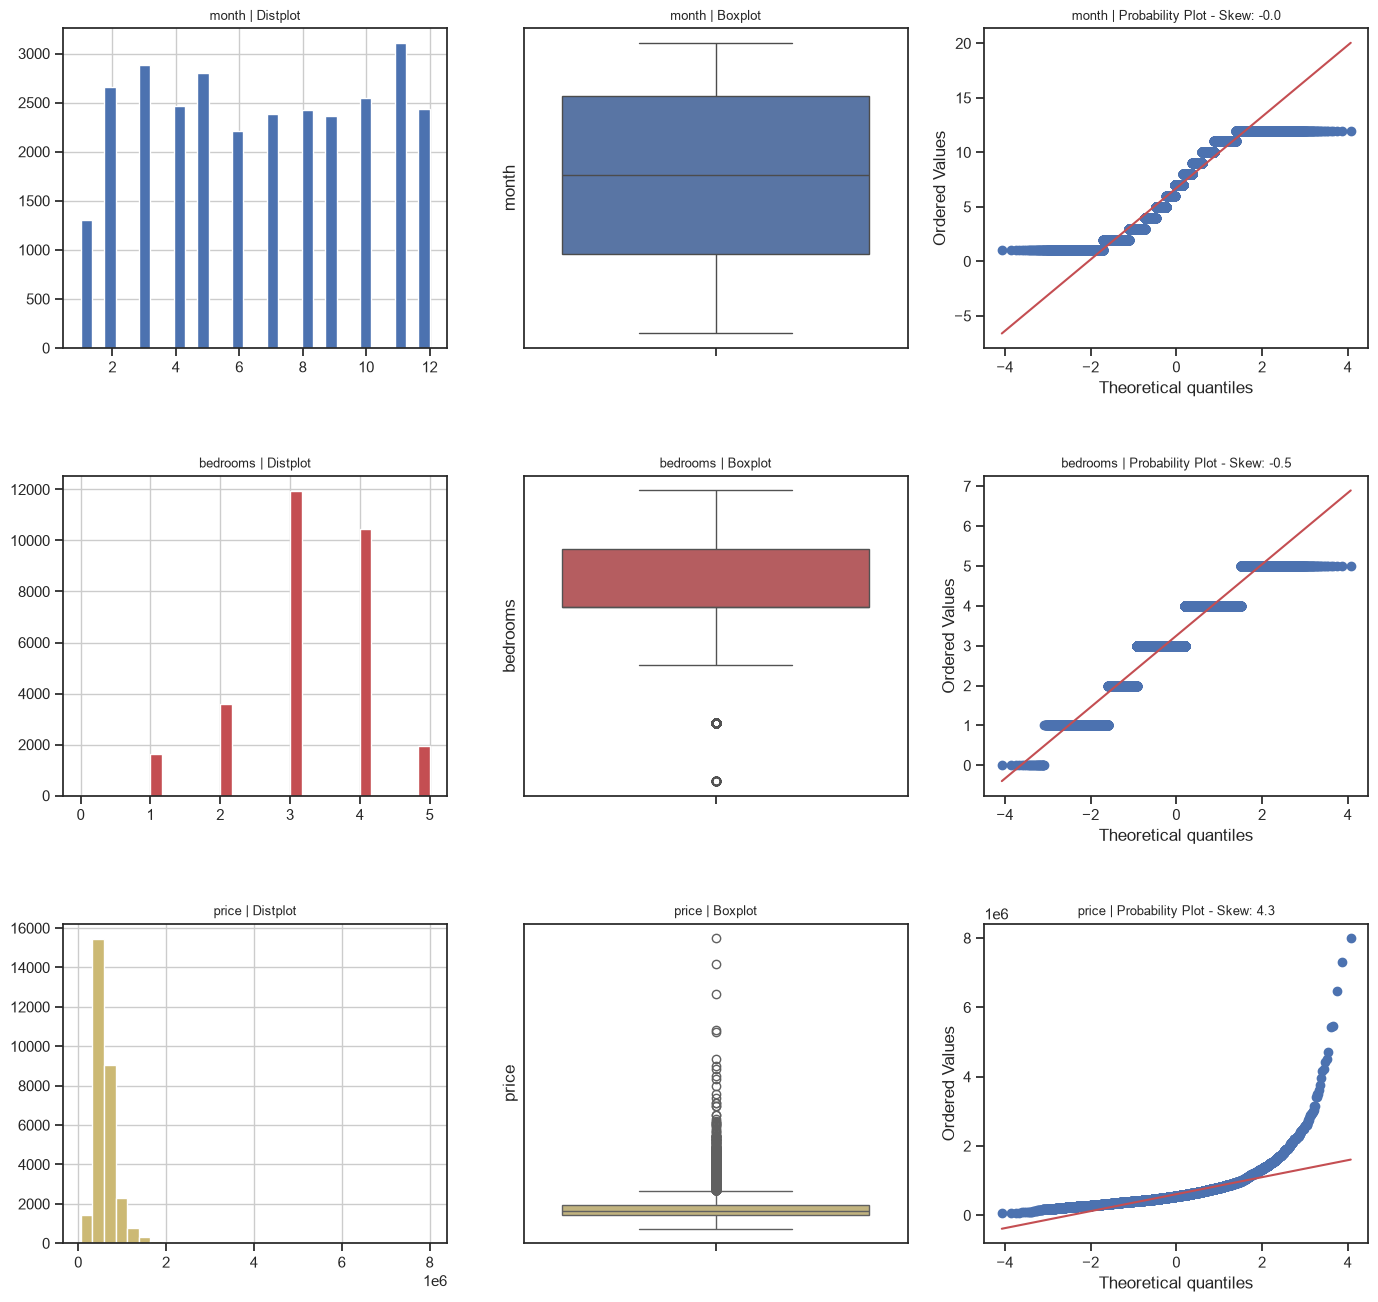

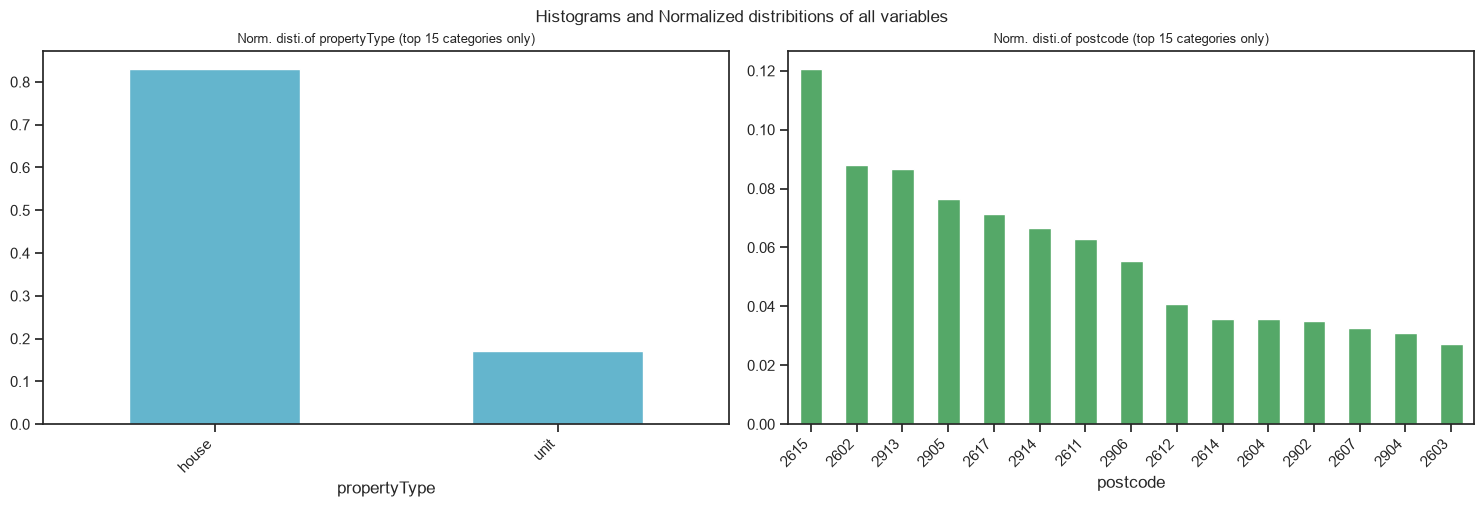

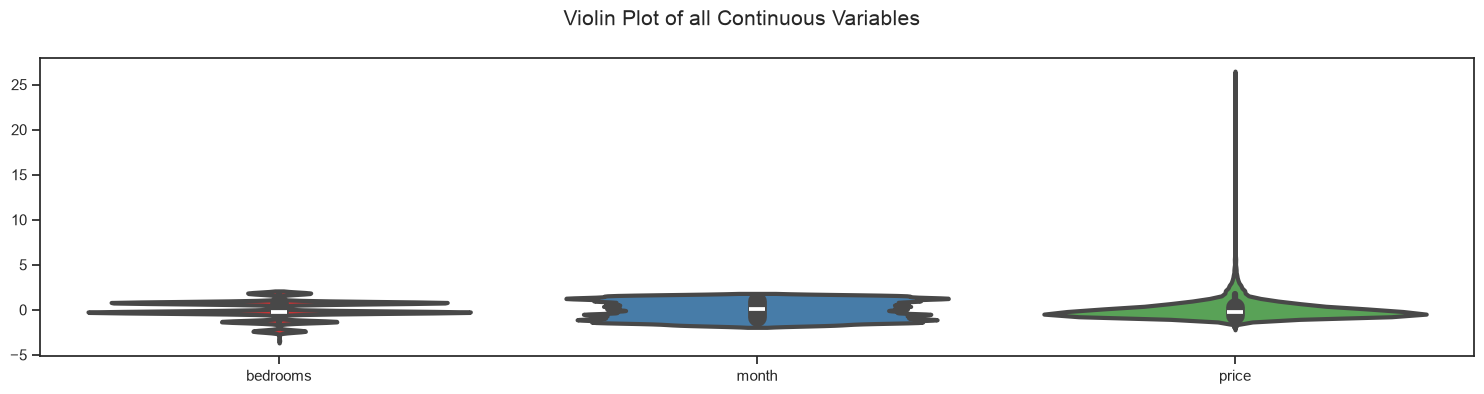

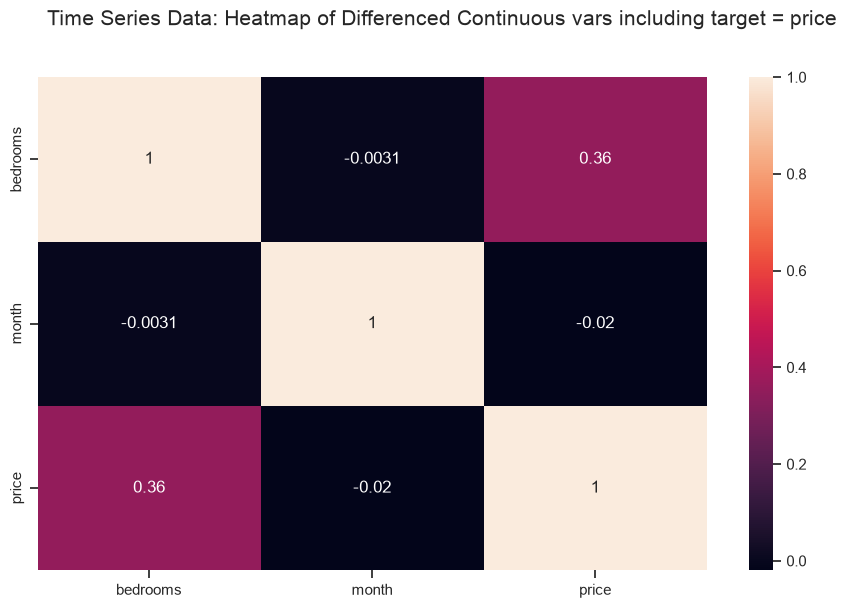

Could not draw some Time Series plots. agg function failed [how->mean,dtype->object]


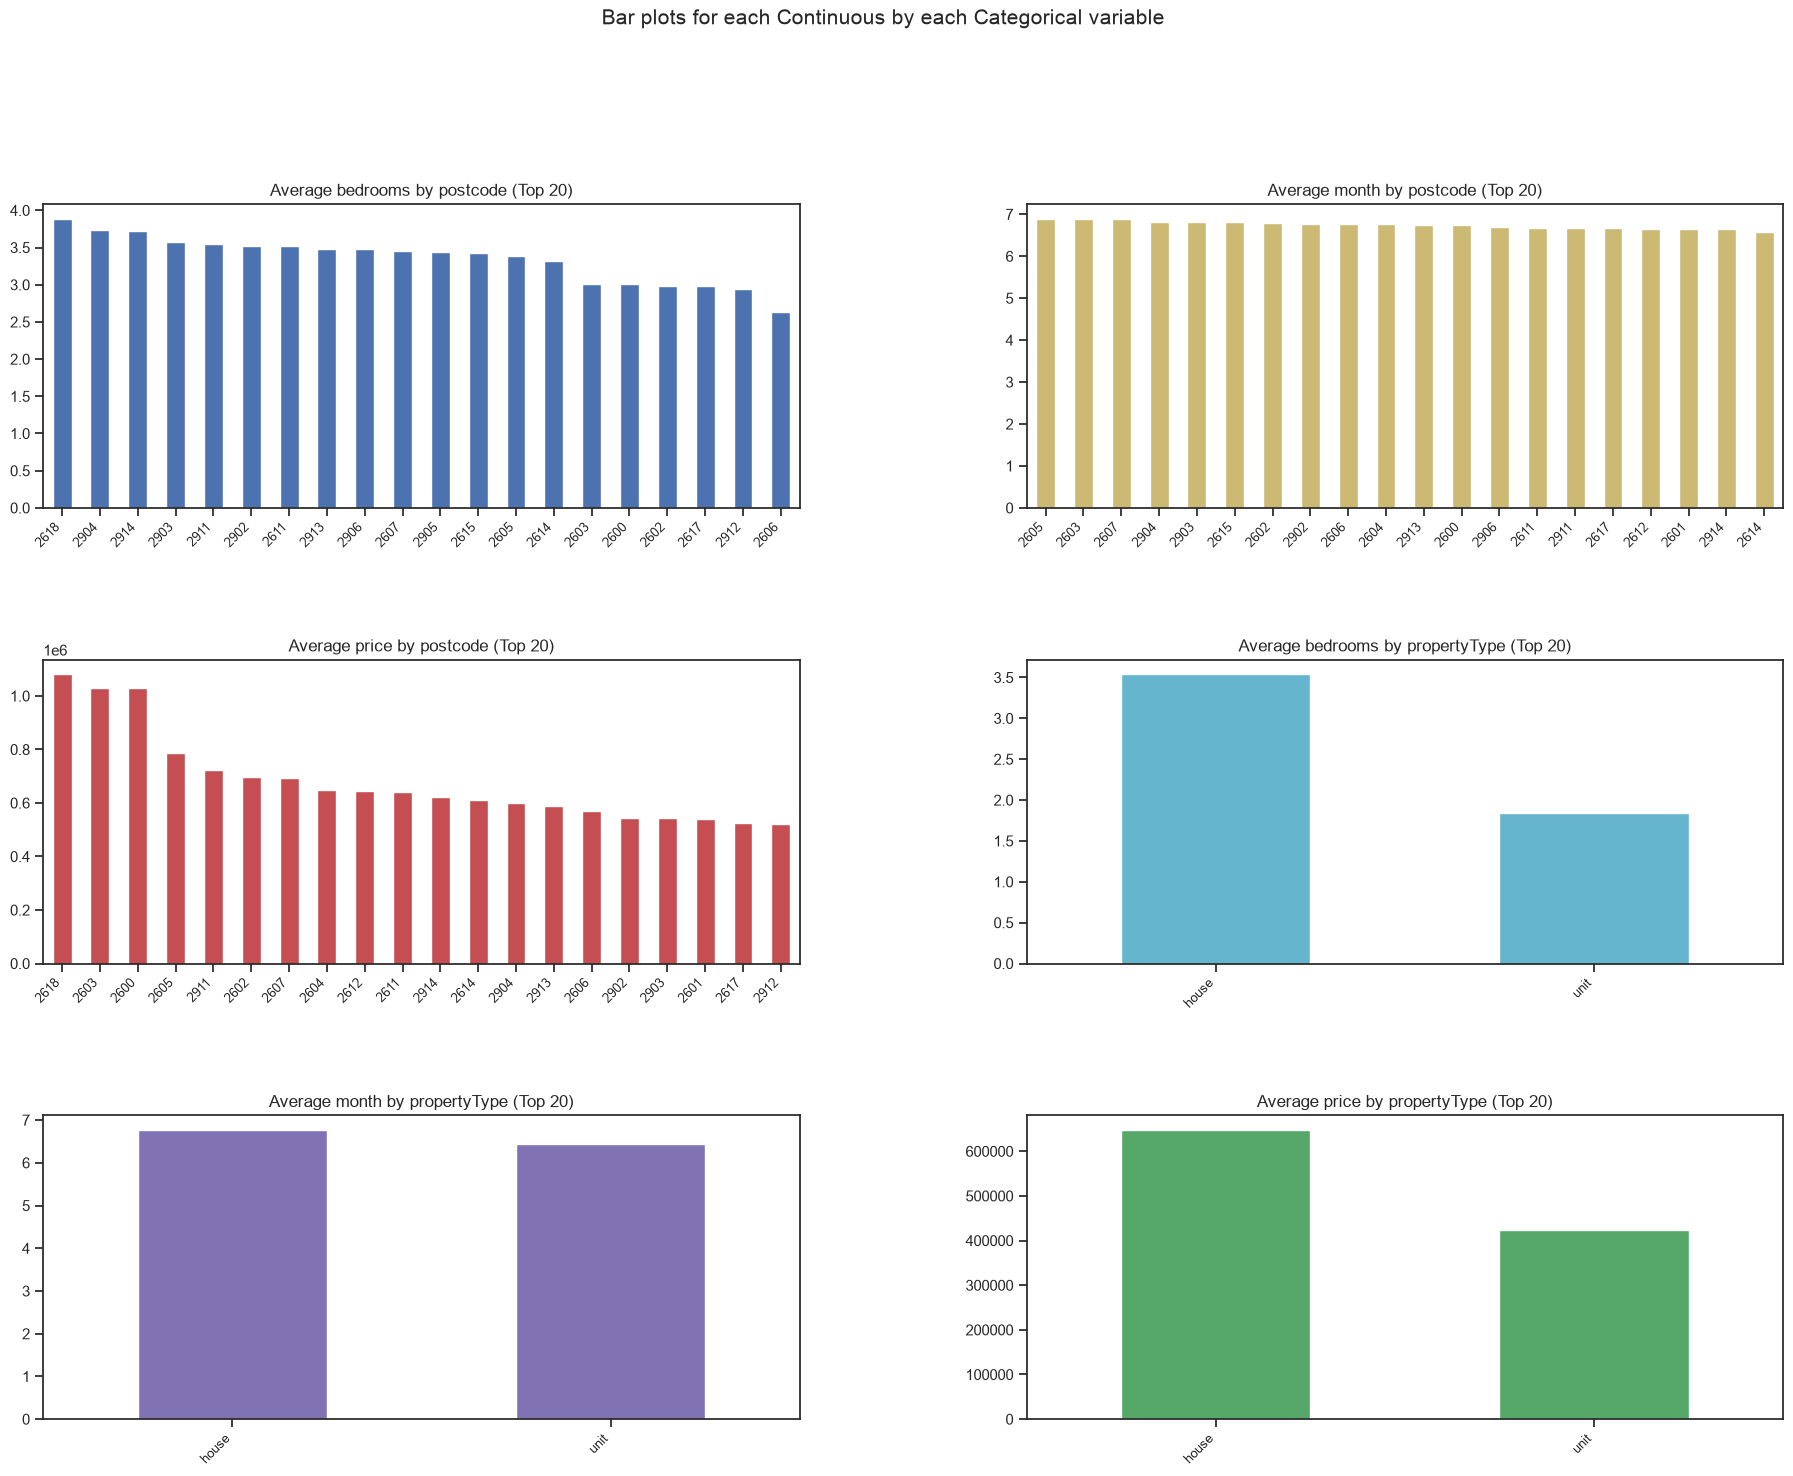

All Plots done
Time to run AutoViz = 2 seconds 

 ###################### AUTO VISUALIZATION Completed ########################


In [13]:
if RUN_AUTOVIZ:
    from autoviz import AutoViz_Class
    %matplotlib inline
    # NB: importing autoviz switches matplotlib to the non-interactive 'agg' backend, so inline plotting is
    # re-enabled straight after the import (and again below for the rest of the notebook).
    AV = AutoViz_Class()
    av_df = raw.assign(year=raw["datesold"].dt.year, month=raw["datesold"].dt.month,
                       postcode=raw["postcode"].astype(str)).drop(columns="datesold")
    _ = AV.AutoViz(filename="", dfte=av_df, depVar="price", verbose=1, chart_format="png",
                   max_rows_analyzed=30000, max_cols_analyzed=10)
%matplotlib inline

> ✍️ **Your observations (AutoViz vs manual):** what did AutoViz flag (skew, outliers, high-cardinality postcode)? What can't it see because it ignores time ordering?

## 5. Transaction-level cleaning
### 5.1 Duplicates and types

In [14]:
clean_log = []


def log_step(step, before, after, reason):
    clean_log.append({"step": step, "rows_before": before, "rows_after": after,
                      "rows_removed": before - after, "reason": reason})


tx = raw.sort_values("datesold").reset_index(drop=True).copy()
n = len(tx); tx = tx.drop_duplicates()
log_step("Drop exact duplicates", n, len(tx), "double-recorded sales")
tx["postcode"] = tx["postcode"].astype(str)          # a postcode is a label, not a number
tx["log_price"] = np.log(tx["price"])
tx["year"] = tx["datesold"].dt.year
tx["t"] = tx["datesold"].dt.year + tx["datesold"].dt.dayofyear / 366   # decimal year
log_step("postcode → string; add log_price, year, decimal time", len(tx), len(tx), "correct types for analysis")

### 5.2 Imputing implausible bedroom counts (KNN)
A *house* with 0 bedrooms is a data-entry error. These values are set to missing and imputed with a **KNN classifier** trained on other houses, using log price, sale time and the postcode's typical price level. Similar houses sold at a similar price, place and time most likely have the same number of bedrooms.

In [15]:
bad_bed = (tx["propertyType"] == "house") & (tx["bedrooms"] == 0)
tx.loc[bad_bed, "bedrooms"] = np.nan
houses_known = tx[(tx["propertyType"] == "house") & tx["bedrooms"].notna()]
pc_level = houses_known.groupby("postcode")["log_price"].median()


def bed_features(d):
    return np.column_stack([d["log_price"], d["t"], d["postcode"].map(pc_level).fillna(pc_level.median())])


bed_scaler = StandardScaler().fit(bed_features(houses_known))
knn_bed = KNeighborsClassifier(n_neighbors=15).fit(bed_scaler.transform(bed_features(houses_known)),
                                                   houses_known["bedrooms"].astype(int))
tx.loc[bad_bed, "bedrooms"] = knn_bed.predict(bed_scaler.transform(bed_features(tx[bad_bed])))
tx["bedrooms"] = tx["bedrooms"].astype(int)
display(tx.loc[bad_bed, ["datesold", "postcode", "price", "bedrooms"]].head(10))
log_step("House bedrooms 0 → KNN-imputed", len(tx), len(tx), f"{bad_bed.sum()} implausible values")

,datesold,postcode,price,bedrooms
6583,2012-09-10,2913,415000,3
7382,2013-02-02,2605,840000,4
7401,2013-02-06,2604,490000,3
7892,2013-05-07,2600,725000,3
8184,2013-06-28,2606,630000,3
8316,2013-07-18,2602,620000,3
8513,2013-08-17,2617,543000,3
11995,2014-12-03,2615,405000,3
12312,2015-01-27,2906,525000,4
12342,2015-01-31,2602,700000,3


### 5.3 Fix the time window and the train/test boundary first
The anomaly rule below **learns thresholds from data**, so the train/test boundary must exist before it. Both the window and the boundary depend only on the weekly sales *counts*, so they are fixed now from the raw counts:
* **start** = first week from which the 8-week rolling median of house sales is ≥ `MIN_SALES_PER_WEEK` (earlier weeks are too sparse)
* **end** = last complete week (the final partial week is dropped)
* **test** = the last `TEST_FRACTION` of weeks

In [16]:
raw_wk = raw[raw["propertyType"] == "house"].set_index("datesold")["price"].resample("W-SUN").size()
START_DATE = raw_wk.index[raw_wk.rolling(8).median() >= MIN_SALES_PER_WEEK].min()
END_WEEK = raw_wk.index[-1] if raw["datesold"].max() >= raw_wk.index[-1] else raw_wk.index[-2]
WEEKS = raw_wk.loc[START_DATE:END_WEEK].index
SPLIT_DATE = WEEKS[int(len(WEEKS) * (1 - TEST_FRACTION))]
print(f"Series window {START_DATE.date()} → {END_WEEK.date()} ({len(WEEKS)} weeks) | test starts {SPLIT_DATE.date()}")

Series window 2008-09-07 → 2019-07-21 (568 weeks) | test starts 2017-05-21


### 5.4 Price anomalies: postcode-aware modified z-score (thresholds learned on training years)
A sale is an anomaly if it is far from **comparable sales**. Two things make sales comparable:
1. **When:** prices rise over time, so each sale is first expressed relative to the market. Its residual is $r_i = \log P_i - \operatorname{median}(\log P)$ over all sales of the same type in the same **quarter**.
2. **What and where:** that residual is then compared with other sales of the same **type × bedrooms × postcode**. Expensive suburbs are normal for their postcode. A rule that ignores postcode would delete them as "outliers" and bias the median price downwards (shown below).

The robust modified z-score (Iglewicz & Hoaglin) is $M_i = 0.6745\,(r_i - \operatorname{median}_g)/\operatorname{MAD}_g$, with $|M_i| > 3.5 \Rightarrow$ anomaly. The group medians and MADs are learned on **training-period sales only** and applied to every sale. Groups with fewer than 20 training sales fall back to type × bedrooms.

Peer group used: postcode-level for 97% of sales, type × bedrooms fallback for the rest


,sales flagged,too expensive,too cheap,share in top-20% priced postcodes
postcode-blind (type × beds × year),712.0,683.0,29.0,0.708
postcode-aware (used),303.0,209.0,94.0,0.205


Top-20% priced postcodes hold 12.4% of all sales.


isolation forest,False,True
modified z,,
False,29004,273
True,280,23


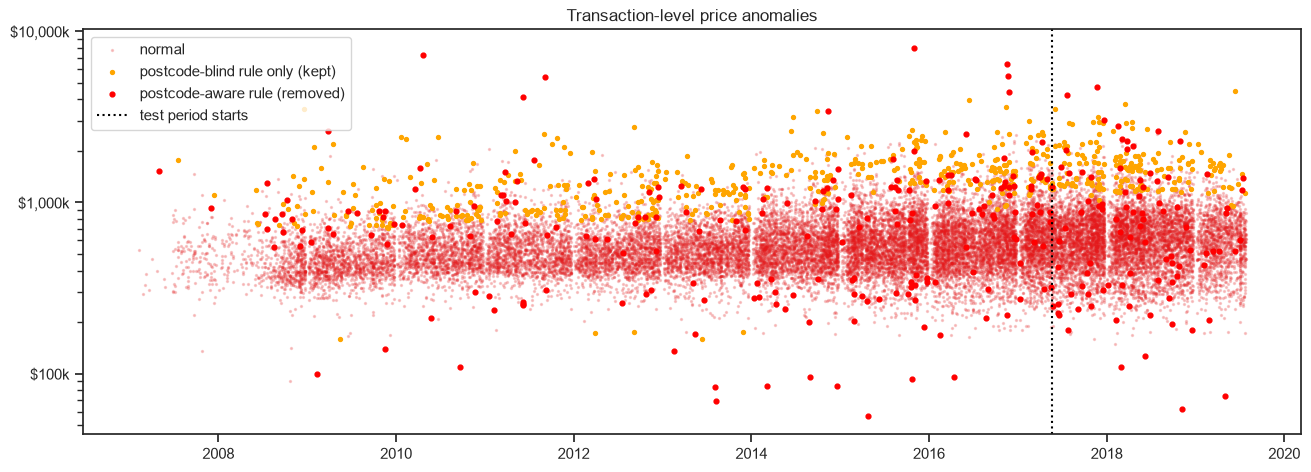

,datesold,postcode,propertyType,bedrooms,price,mod_z
29011,2019-05-03,2912,house,4,74000,-22.429300
27714,2018-11-06,2615,house,4,62000,-18.275927
8441,2013-08-07,2605,house,3,69000,-14.807740
13215,2015-04-24,2611,house,4,56500,-13.145537
12179,2014-12-18,2612,unit,1,85000,-13.130574
926,2009-02-11,2905,house,3,100000,-12.203612
11095,2014-08-29,2612,unit,1,95000,-11.726696
8433,2013-08-06,2600,house,3,84000,-11.617303


,datesold,postcode,propertyType,bedrooms,price,mod_z
10427,2014-05-26,2605,unit,3,991000,8.008041
25977,2018-05-19,2903,house,3,1350000,8.341737
15186,2015-11-02,2611,house,4,8000000,12.840812
27626,2018-10-29,2617,unit,1,2280000,18.128982
17490,2016-06-03,2607,unit,2,2500000,18.877260
4481,2011-06-06,2902,house,3,4150000,21.266028
4878,2011-09-07,2912,house,4,5425000,21.802211
19273,2016-11-19,2611,house,3,6480000,22.084275


In [17]:
MIN_GROUP = 20
tx = tx.reset_index(drop=True)
tx["quarter"] = tx["datesold"].dt.to_period("Q")
tx["resid"] = tx["log_price"] - tx.groupby(["propertyType", "quarter"])["log_price"].transform("median")
fit = tx[tx["datesold"] < SPLIT_DATE]
mad = lambda s: (s - s.median()).abs().median()
fine = fit.groupby(["propertyType", "bedrooms", "postcode"])["resid"].agg(med="median", mad=mad, n="size").reset_index()
coarse = fit.groupby(["propertyType", "bedrooms"])["resid"].agg(med_c="median", mad_c=mad).reset_index()
tx = tx.merge(fine, on=["propertyType", "bedrooms", "postcode"], how="left").merge(coarse, on=["propertyType", "bedrooms"], how="left")
use_fine = (tx["n"] >= MIN_GROUP) & (tx["mad"] > 0)
g_med, g_mad = np.where(use_fine, tx["med"], tx["med_c"]), np.where(use_fine, tx["mad"], tx["mad_c"])
tx["mod_z"] = 0.6745 * (tx["resid"] - g_med) / pd.Series(g_mad).replace(0, np.nan)
tx["anom_mz"] = tx["mod_z"].abs() > 3.5
print(f"Peer group used: postcode-level for {use_fine.mean():.0%} of sales, type × bedrooms fallback for the rest")

# The previous, postcode-blind rule (type × bedrooms × year) for comparison
old_grp = tx.groupby(["propertyType", "bedrooms", "year"])["log_price"]
old_z = (0.6745 * (tx["log_price"] - old_grp.transform("median")) / old_grp.transform(mad).replace(0, np.nan)).where(old_grp.transform("size") >= 20)
pc_level = tx[tx["propertyType"] == "house"].groupby("postcode")["price"].median()
premium = tx["postcode"].isin(pc_level[pc_level >= pc_level.quantile(0.8)].index)


def rule_summary(flag, z):
    return {"sales flagged": int(flag.sum()), "too expensive": int((flag & (z > 0)).sum()), "too cheap": int((flag & (z < 0)).sum()),
            "share in top-20% priced postcodes": round(premium[flag].mean(), 3)}


display(pd.DataFrame({"postcode-blind (type × beds × year)": rule_summary(old_z.abs() > 3.5, old_z),
                      "postcode-aware (used)": rule_summary(tx["anom_mz"], tx["mod_z"])}).T)
print(f"Top-20% priced postcodes hold {premium.mean():.1%} of all sales.")

iso_X = StandardScaler().fit_transform(np.column_stack([
    tx["log_price"], tx["bedrooms"], (tx["propertyType"] == "house").astype(int), tx["t"],
    tx["postcode"].map(tx.groupby("postcode")["log_price"].median())]))
tx["anom_iso"] = IsolationForest(n_estimators=300, contamination=0.01, random_state=RANDOM_STATE).fit_predict(iso_X) == -1
display(pd.crosstab(tx["anom_mz"], tx["anom_iso"], rownames=["modified z"], colnames=["isolation forest"]))

fig, ax = plt.subplots(figsize=(14, 5))
ax.scatter(tx["datesold"], tx["price"], s=2, alpha=.2, label="normal")
ax.scatter(tx.loc[(old_z.abs() > 3.5) & ~tx["anom_mz"], "datesold"], tx.loc[(old_z.abs() > 3.5) & ~tx["anom_mz"], "price"],
           s=8, c="orange", label="postcode-blind rule only (kept)")
ax.scatter(tx.loc[tx["anom_mz"], "datesold"], tx.loc[tx["anom_mz"], "price"], s=12, c="red", label="postcode-aware rule (removed)")
ax.axvline(SPLIT_DATE, color="black", ls=":", label="test period starts")
ax.set_yscale("log")
ax.yaxis.set_major_formatter(dollars)
ax.set_title("Transaction-level price anomalies")
ax.legend()
plt.show()
cols = ["datesold", "postcode", "propertyType", "bedrooms", "price", "mod_z"]
display(tx[tx["anom_mz"]].sort_values("mod_z")[cols].head(8))
display(tx[tx["anom_mz"]].sort_values("mod_z")[cols].tail(8))

Compare the two rules. The postcode-blind rule mostly removed **expensive sales in expensive postcodes**: real market activity, not errors. The postcode-aware rule flags far fewer sales, and those are extreme even for their own suburb (e.g. a house selling for a fraction of its neighbours' prices). The Isolation Forest also flags many sales that are merely **old and cheap** or **new and expensive**, so it is used only as a cross-check.

In [18]:
n = len(tx)
tx = tx[~tx["anom_mz"]].drop(columns=["anom_mz", "anom_iso", "mod_z", "resid", "quarter", "med", "mad", "n", "med_c", "mad_c"])
log_step("Remove postcode-aware price anomalies (|M|>3.5)", n, len(tx), "far from comparable sales in the same suburb and quarter")
pd.DataFrame(clean_log)

,step,rows_before,rows_after,rows_removed,reason
0,Drop exact duplicates,29580,29580,0,double-recorded sales
1,"postcode → string; add log_price, year, decimal time",29580,29580,0,correct types for analysis
2,House bedrooms 0 → KNN-imputed,29580,29580,0,19 implausible values
3,Remove postcode-aware price anomalies (|M|>3.5),29580,29277,303,far from comparable sales in the same suburb and quarter


## 6. Build the weekly series
* **Target series:** weekly median **house** price (houses are about 80% of sales and a different market from units), over the window fixed in 5.3.
* Weeks with fewer than `MIN_SALES_PER_WEEK` sales (e.g. the Christmas break) get a **missing** median, because a median of 2 or 3 sales is mostly noise. These gaps are imputed in section 7.

In [19]:
houses = tx[tx["propertyType"] == "house"].set_index("datesold")
weekly = pd.DataFrame({"median_price": houses["price"].resample("W-SUN").median(),
                       "n_sales": houses["price"].resample("W-SUN").size()}).reindex(WEEKS)
weekly["n_sales"] = weekly["n_sales"].fillna(0).astype(int)
weekly["observed"] = weekly["n_sales"] >= MIN_SALES_PER_WEEK
weekly.loc[~weekly["observed"], "median_price"] = np.nan
print(f"Series: {weekly.index.min().date()} → {weekly.index.max().date()}, {len(weekly)} weeks")
print(f"Missing (low-count) weeks: {(~weekly['observed']).sum()}")
display(weekly[~weekly["observed"]].head(12))

Series: 2008-09-07 → 2019-07-21, 568 weeks
Missing (low-count) weeks: 21


,median_price,n_sales,observed
datesold,,,
2008-09-14,NaN,9,False
2009-01-04,NaN,0,False
2010-01-03,NaN,0,False
2010-01-10,NaN,7,False
2010-01-17,NaN,9,False
2011-01-02,NaN,0,False
2011-01-09,NaN,9,False
2012-01-01,NaN,0,False
2012-01-08,NaN,7,False


### 6.1 Chronological train/test split
The split date was fixed in 5.3, **before** anomaly thresholds, imputation or series-level cleaning, so nothing learned from the test period can influence training.

Train: 2008-09-07 → 2017-05-14 (454 weeks)
Test:  2017-05-21 → 2019-07-21 (114 weeks)


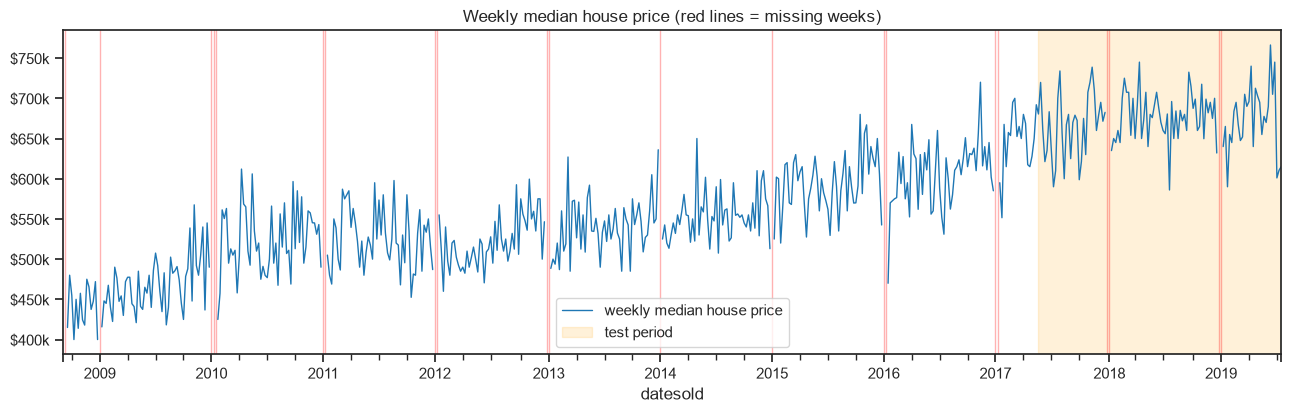

In [20]:
is_train = weekly.index < SPLIT_DATE
print(f"Train: {weekly.index[is_train].min().date()} → {weekly.index[is_train].max().date()} ({is_train.sum()} weeks)")
print(f"Test:  {SPLIT_DATE.date()} → {weekly.index.max().date()} ({(~is_train).sum()} weeks)")

ax = weekly["median_price"].plot(figsize=(14, 4), lw=1, color="tab:blue", label="weekly median house price")
ax.axvspan(SPLIT_DATE, weekly.index.max(), color="orange", alpha=.15, label="test period")
for d in weekly.index[~weekly["observed"]]:
    ax.axvline(d, color="red", alpha=.3, lw=1)
ax.yaxis.set_major_formatter(dollars)
ax.set_title("Weekly median house price (red lines = missing weeks)")
ax.legend()
plt.show()

## 7. Imputation of missing weeks
Candidate methods are evaluated by **hiding 10% of the observed training weeks**, imputing them and measuring the error:

| Method | Uses future weeks? |
|---|---|
| Forward fill (last observed week) | no (causal) |
| Trailing median of the previous 8 weeks | no (causal) |
| Linear interpolation between neighbouring weeks | **yes** |
| Centred 9-week rolling median | **yes** (up to 4 weeks ahead) |

**Only causal methods are allowed** for the modelling series. The imputed values become lag features. A non-causal fill for week *t* would let the lag-1 feature at week *t+1* contain information about week *t+1* itself (and beyond), which is **target leakage**. The non-causal methods are still scored so the cost of this rule is visible.

In [21]:
CAUSAL = {"ffill": True, "trailing_median": True, "linear": False, "centred_median": False}


def impute_series(s, method):
    if method == "ffill":
        return s.ffill().bfill()
    if method == "trailing_median":
        return s.fillna(s.shift(1).rolling(8, min_periods=1).median()).ffill().bfill()
    if method == "linear":
        return s.interpolate("linear").ffill().bfill()
    if method == "centred_median":
        return s.fillna(s.rolling(9, center=True, min_periods=1).median()).ffill().bfill()
    raise ValueError(method)


y_tr = weekly.loc[is_train, "median_price"]
obs_idx = y_tr.dropna().index
mask = pd.Index(np.random.default_rng(RANDOM_STATE).choice(obs_idx, size=int(0.1 * len(obs_idx)), replace=False))
masked = y_tr.copy()
masked[mask] = np.nan
imp_res = pd.DataFrame({m: {"MAE": mean_absolute_error(y_tr[mask], impute_series(masked, m)[mask]),
                            "RMSE": np.sqrt(mean_squared_error(y_tr[mask], impute_series(masked, m)[mask])),
                            "causal": CAUSAL[m]}
                        for m in CAUSAL}).T.sort_values("MAE")
BEST_IMPUTER = imp_res[imp_res["causal"].astype(bool)].index[0]
display(imp_res)
print("Selected (best causal) imputer:", BEST_IMPUTER)

# a causal fill never looks forward, so the whole series can be filled in one pass without leaking test into train
weekly["price_clean"] = impute_series(weekly["median_price"], BEST_IMPUTER)
assert weekly["price_clean"].notna().all()

,MAE,RMSE,causal
trailing_median,28110.755814,39225.593758,True
centred_median,30064.127907,36428.54336,False
linear,33552.445736,39941.920031,False
ffill,37088.72093,46284.76567,True


Selected (best causal) imputer: trailing_median


## 8. Time-series EDA
### 8.1 Rolling statistics

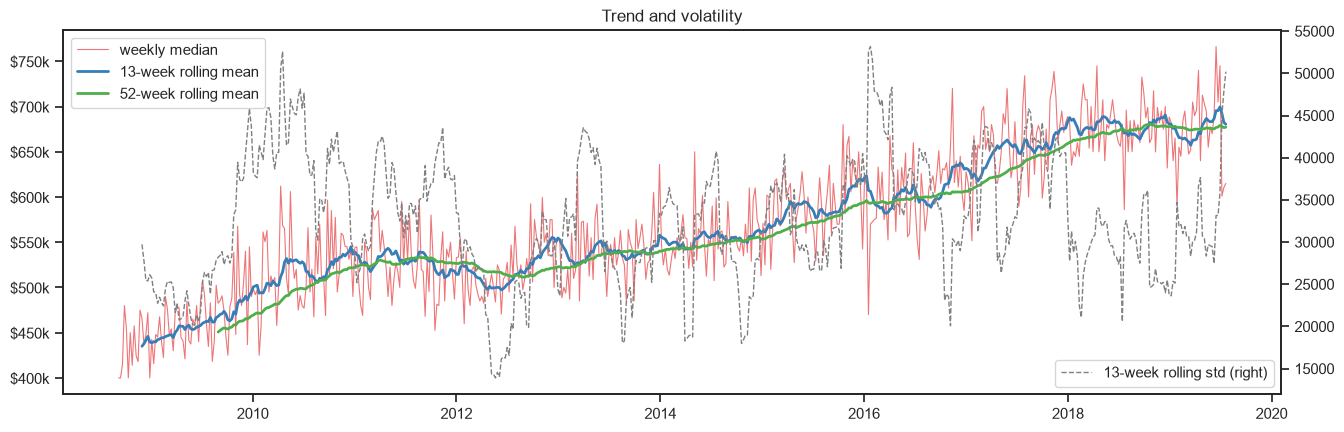

In [22]:
y = weekly["price_clean"]
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(y, lw=.8, alpha=.6, label="weekly median")
ax.plot(y.rolling(13).mean(), lw=2, label="13-week rolling mean")
ax.plot(y.rolling(52).mean(), lw=2, label="52-week rolling mean")
ax2 = ax.twinx()
ax2.plot(y.rolling(13).std(), color="grey", lw=1, ls="--", label="13-week rolling std (right)")
ax.yaxis.set_major_formatter(dollars)
ax.set_title("Trend and volatility")
ax.legend(loc="upper left")
ax2.legend(loc="lower right")
plt.show()

### 8.2 STL decomposition (trend + yearly seasonality + residual)

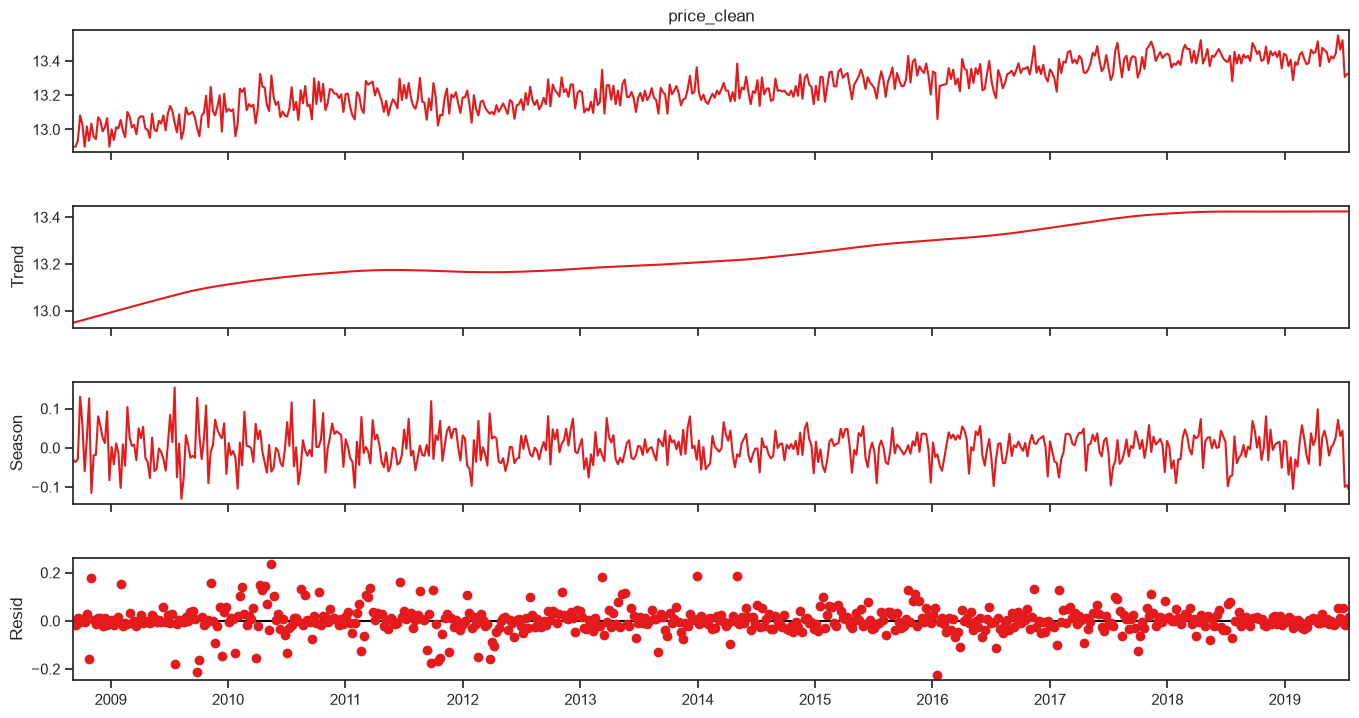

Strength of trend: 0.84 | strength of yearly seasonality: 0.22  (0 = none, 1 = dominant)


In [23]:
stl_full = STL(np.log(y), period=52, robust=True).fit()
fig = stl_full.plot()
fig.set_size_inches(14, 8)
plt.show()
strength_trend = max(0, 1 - stl_full.resid.var() / (stl_full.trend + stl_full.resid).var())
strength_season = max(0, 1 - stl_full.resid.var() / (stl_full.seasonal + stl_full.resid).var())
print(f"Strength of trend: {strength_trend:.2f} | strength of yearly seasonality: {strength_season:.2f}  (0 = none, 1 = dominant)")

### 8.3 Stationarity (Augmented Dickey-Fuller) and autocorrelation

,series,ADF statistic,p-value,stationary (p<0.05)
0,price level,-1.187,0.6793,False
1,"log price, 1st difference",-10.284,0.0000,True
2,price / trailing 13-wk mean − 1 (our target),-9.661,0.0000,True


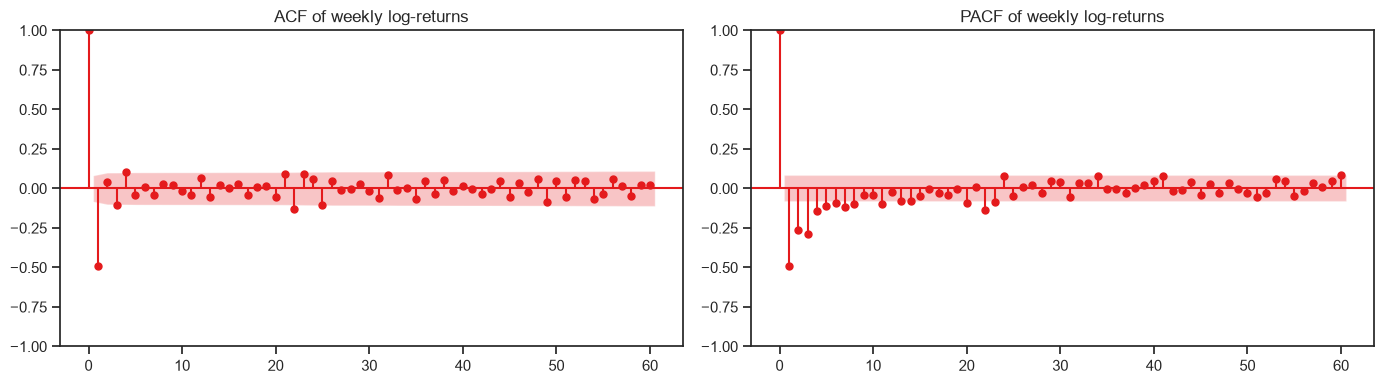

In [24]:
def adf_row(s, name):
    stat, p, *_ = adfuller(s.dropna(), autolag="AIC")
    return {"series": name, "ADF statistic": round(stat, 3), "p-value": round(p, 4), "stationary (p<0.05)": p < 0.05}


rel13 = y / y.shift(1).rolling(13).mean() - 1
display(pd.DataFrame([adf_row(y, "price level"), adf_row(np.log(y).diff(), "log price, 1st difference"),
                      adf_row(rel13, "price / trailing 13-wk mean − 1  (our target)")]))
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(np.log(y).diff().dropna(), lags=60, ax=axes[0])
plot_pacf(np.log(y).diff().dropna(), lags=60, ax=axes[1], method="ywm")
axes[0].set_title("ACF of weekly log-returns")
axes[1].set_title("PACF of weekly log-returns")
plt.tight_layout()
plt.show()

### 8.4 Sanity check against the publisher's series
The quarterly median of **our cleaned** 3-bedroom house data is compared with the publisher's moving average (`ma_lga`). If they agree, the cleaning didn't distort the market signal.

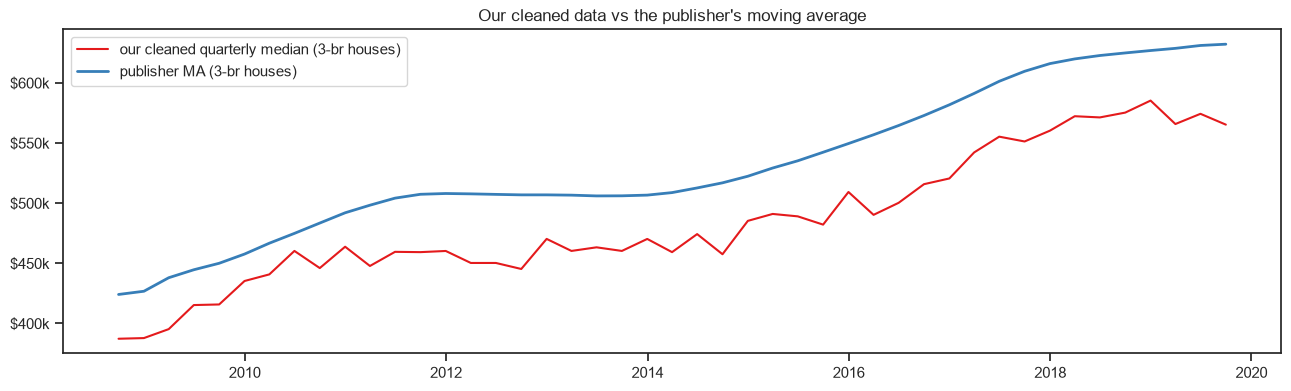

Correlation of the two quarterly series: 0.915


In [25]:
ours = tx[(tx["propertyType"] == "house") & (tx["bedrooms"] == 3)].set_index("datesold")["price"].resample("QE").median()
theirs = ma[(ma["type"] == "house") & (ma["bedrooms"] == 3)].set_index("saledate")["MA"]
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(ours.loc[START_DATE:], label="our cleaned quarterly median (3-br houses)")
ax.plot(theirs.loc[START_DATE:], label="publisher MA (3-br houses)", lw=2)
ax.yaxis.set_major_formatter(dollars)
ax.legend()
ax.set_title("Our cleaned data vs the publisher's moving average")
plt.show()
both = pd.concat([ours, theirs], axis=1, keys=["ours", "theirs"]).dropna()
print(f"Correlation of the two quarterly series: {both.corr().iloc[0, 1]:.3f}")

> ✍️ **Your observations (time-series EDA):** how strong are the trend and seasonality? Is the price level stationary, and does the relative target fix that? What do ACF and PACF say about how many lags matter?

## 9. Series-level anomaly removal (training period only)
Even after transaction cleaning, a week can be unusual (e.g. a few luxury sales in a low-volume week). These are found as large residuals of a **robust STL** decomposition, **fit on the training period only**, using a 3σ rule on the residual of log price.

*Why 3σ and not the modified z-score used in 5.3?* Robust STL deliberately leaves outliers in the residual, which makes the residual's MAD very small. A MAD-based rule would then flag about 6% of all weeks. The 3σ rule flags about 2%, which matches what the plot shows by eye.

Flagged weeks are replaced with the chosen imputer. The test period is left as observed, so the model is evaluated on reality.

11 anomalous training weeks: ['2008-11-02', '2009-07-19', '2009-09-27', '2009-10-04', '2010-05-16', '2011-09-25', '2011-10-16', '2013-03-10', '2013-12-29', '2014-05-04', '2016-01-17']


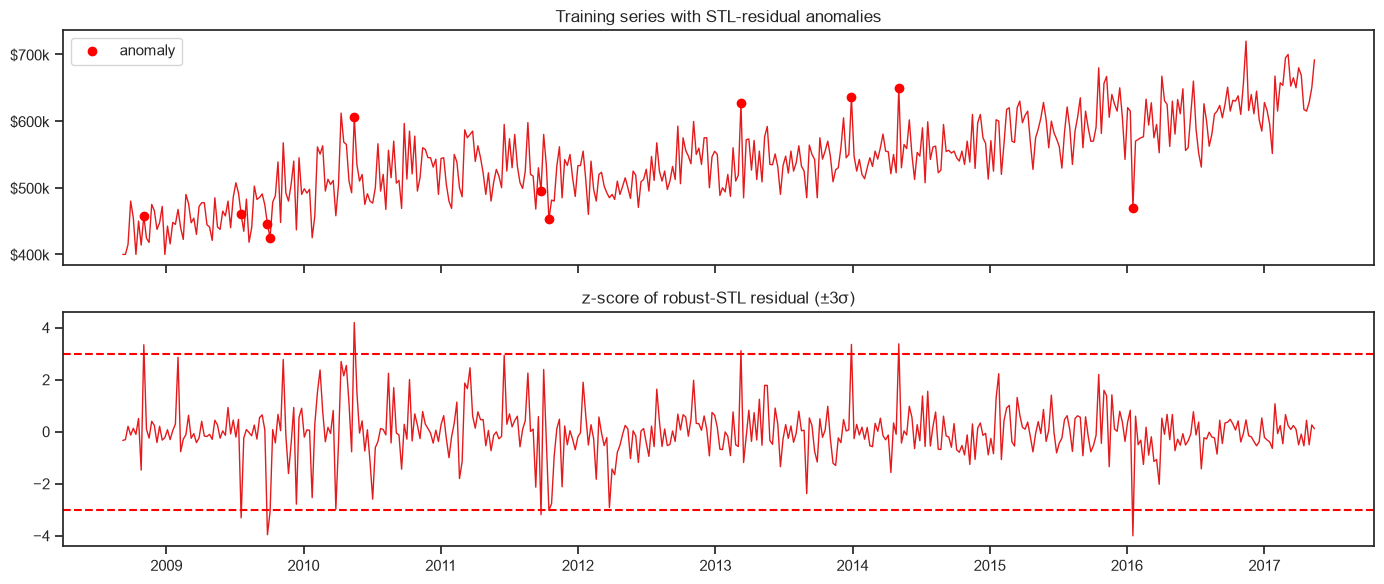

In [26]:
y_train = weekly.loc[is_train, "price_clean"]
stl_tr = STL(np.log(y_train), period=52, robust=True).fit()
r = stl_tr.resid
rz = (r - r.mean()) / r.std()
anom_weeks = rz.index[rz.abs() > 3]
print(f"{len(anom_weeks)} anomalous training weeks:", [d.date().isoformat() for d in anom_weeks])

fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
axes[0].plot(y_train, lw=1)
axes[0].scatter(anom_weeks, y_train[anom_weeks], c="red", zorder=3, label="anomaly")
axes[0].yaxis.set_major_formatter(dollars)
axes[0].legend()
axes[0].set_title("Training series with STL-residual anomalies")
axes[1].plot(rz, lw=1)
axes[1].axhline(3, c="red", ls="--")
axes[1].axhline(-3, c="red", ls="--")
axes[1].set_title("z-score of robust-STL residual (±3σ)")
plt.tight_layout()
plt.show()

fixed = y_train.copy()
fixed[anom_weeks] = np.nan
weekly.loc[is_train, "price_clean"] = impute_series(fixed, BEST_IMPUTER)

## 10. Clustering: postcodes by price trajectory
Do all suburbs move together? Each postcode is described by its **price-growth curve** (yearly median house price indexed to its first training year = 1) plus its **price level**, using **training years only**. These are clustered with K-Means (*k* by silhouette). The clusters
1. give an insight: which areas boomed and which lagged, and
2. become **features**: last week's median price in each postcode cluster tells the model *where* the market is moving.

19 postcodes have ≥10 house sales in every training year 2009–2016


Silhouette by k: {2: 0.546, 3: 0.624, 4: 0.495, 5: 0.497, 6: 0.469} → k = 3


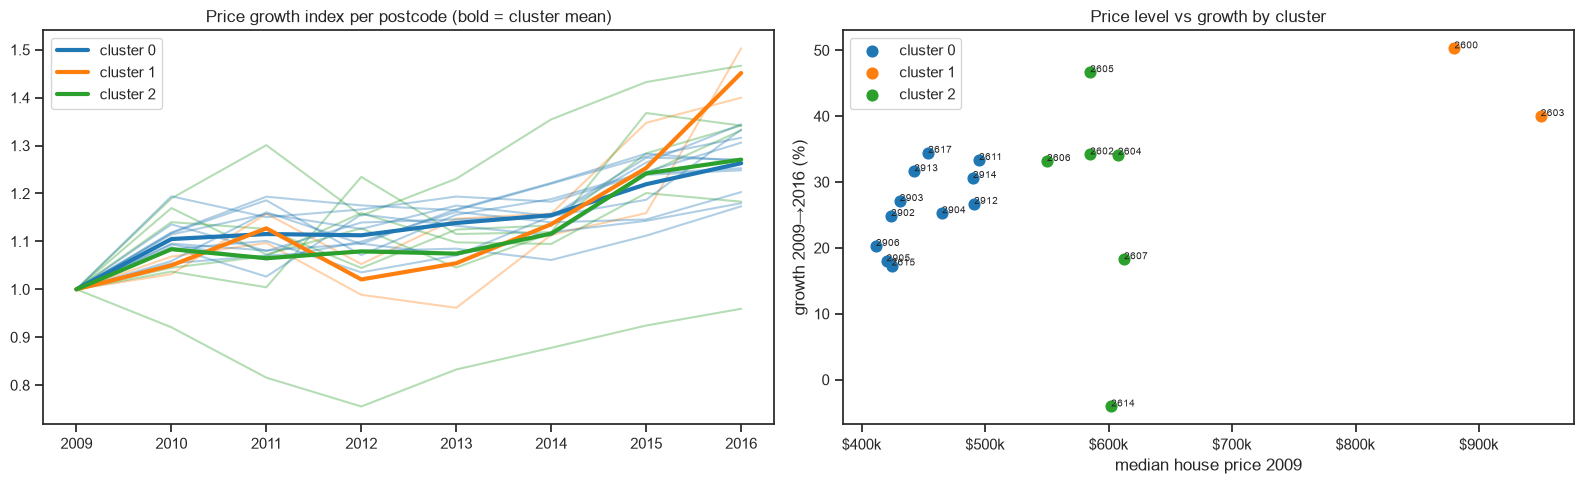

,n_postcodes,median_start,median_growth_pct
cluster,,,
0,11,442500.0,26.7
1,2,915000.0,45.1
2,6,593500.0,33.7


In [27]:
ph = tx[(tx["propertyType"] == "house") & (tx["datesold"] < SPLIT_DATE)]
pv = ph.groupby(["postcode", "year"])["price"].agg(["median", "size"])
med, cnt = pv["median"].unstack(), pv["size"].unstack()
years = [yr for yr in med.columns if START_DATE.year < yr < SPLIT_DATE.year]   # complete training years
eligible = (cnt[years] >= 10).all(axis=1)
traj = med.loc[eligible, years]
growth = traj.div(traj.iloc[:, 0], axis=0)
X_pc = np.column_stack([growth.values, StandardScaler().fit_transform(np.log(traj.iloc[:, [0]]))])
print(f"{eligible.sum()} postcodes have ≥10 house sales in every training year {years[0]}–{years[-1]}")

sils = {k: silhouette_score(X_pc, KMeans(k, n_init=20, random_state=RANDOM_STATE).fit_predict(X_pc))
        for k in range(2, min(7, len(X_pc)))}
K_OVERRIDE = None
PC_K = K_OVERRIDE or max(sils, key=sils.get)
pc_km = KMeans(PC_K, n_init=20, random_state=RANDOM_STATE).fit(X_pc)
pc_cluster = pd.Series(pc_km.labels_, index=traj.index, name="cluster")
print("Silhouette by k:", {k: round(v, 3) for k, v in sils.items()}, "→ k =", PC_K)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
colors = plt.cm.tab10.colors
for pcode, row in growth.iterrows():
    axes[0].plot(years, row.values, color=colors[pc_cluster[pcode]], alpha=.35)
for c in range(PC_K):
    axes[0].plot(years, growth[pc_cluster == c].mean().values, color=colors[c], lw=3, label=f"cluster {c}")
axes[0].set_title("Price growth index per postcode (bold = cluster mean)")
axes[0].legend()
summary = pd.DataFrame({"cluster": pc_cluster, "first_year_median": traj.iloc[:, 0],
                        "last_year_median": traj.iloc[:, -1], "growth_%": (growth.iloc[:, -1] - 1) * 100})
for c in range(PC_K):
    s = summary[summary["cluster"] == c]
    axes[1].scatter(s["first_year_median"], s["growth_%"], color=colors[c], s=60, label=f"cluster {c}")
    for pcode, rr in s.iterrows():
        axes[1].annotate(pcode, (rr["first_year_median"], rr["growth_%"]), fontsize=7)
axes[1].xaxis.set_major_formatter(dollars)
axes[1].set_xlabel(f"median house price {years[0]}")
axes[1].set_ylabel(f"growth {years[0]}→{years[-1]} (%)")
axes[1].set_title("Price level vs growth by cluster")
axes[1].legend()
plt.tight_layout()
plt.show()
summary.groupby("cluster").agg(n_postcodes=("growth_%", "size"), median_start=("first_year_median", "median"),
                               median_growth_pct=("growth_%", "median")).round(1)

> ✍️ **Your observations (clusters):** describe each cluster (e.g. "expensive inner suburbs, slow growth" vs "affordable outer suburbs, fast growth").

## 11. Feature engineering (supervised framing)
**Target.** Tree-based models can't extrapolate. The test period has higher prices than anything seen in training, so predicting the raw price level would fail. Instead the model predicts the **relative deviation from the trailing 13-week mean**:

$$ y^{rel}_t = \frac{P_t}{\bar P_{t-13..t-1}} - 1 \qquad\Rightarrow\qquad \hat P_t = \bar P_{t-13..t-1}\,(1 + \hat y^{rel}_t) $$

The ADF test in 8.3 shows this target is stationary.

**Features** (all known at the end of week *t−1*):
| Group | Features |
|---|---|
| Lags | price lags 1, 2, 3, 4, 8, 13, 26, 52 weeks, each relative to the 13-week base |
| Rolling | 4-vs-13-week momentum, 13-week volatility, 52-week trend ratio |
| Volume | sales count last week, 4-week average |
| Related series | last week's median **unit** price (relative), last week's median price in each **postcode cluster** (relative) |
| Calendar | week of year (sin/cos), month, quarter, holiday-period flag |

In [28]:
units = tx[tx["propertyType"] == "unit"].set_index("datesold")["price"].resample("W-SUN").median().reindex(weekly.index).ffill()
tx_h = tx[tx["propertyType"] == "house"].assign(cluster=lambda d: d["postcode"].map(pc_cluster))
cluster_px = {c: tx_h[tx_h["cluster"] == c].set_index("datesold")["price"].resample("W-SUN").median().reindex(weekly.index).ffill()
              for c in range(PC_K)}


def build_features(p, include_clusters=True):
    """Supervised frame for one-step-ahead forecasting. Every feature at week t uses data up to week t-1 only."""
    base = p.shift(1).rolling(13).mean()
    F = pd.DataFrame(index=p.index)
    F[TARGET] = p / base - 1
    for k in [1, 2, 3, 4, 8, 13, 26, 52]:
        F[f"lag{k}_rel"] = p.shift(k) / base - 1
    F["momentum_4_13"] = p.shift(1).rolling(4).mean() / base - 1
    F["volatility_13"] = p.shift(1).rolling(13).std() / base
    F["trend_13_52"] = base / p.shift(1).rolling(52).mean() - 1
    F["n_sales_lag1"] = weekly["n_sales"].shift(1)
    F["n_sales_roll4"] = weekly["n_sales"].shift(1).rolling(4).mean()
    F["unit_rel_lag1"] = units.shift(1) / units.shift(1).rolling(13).mean() - 1
    if include_clusters:
        for c, cp in cluster_px.items():
            F[f"cluster{c}_rel_lag1"] = cp.shift(1) / base - 1
    wk = p.index.isocalendar().week.astype(int).values
    F["week_sin"], F["week_cos"] = np.sin(2 * np.pi * wk / 52), np.cos(2 * np.pi * wk / 52)
    F["month"], F["quarter"] = p.index.month, p.index.quarter
    F["holiday_period"] = np.isin(wk, [51, 52, 53, 1, 2]).astype(int)
    F["_base"], F["_actual"], F["_observed"] = base, weekly["median_price"], weekly["observed"]   # helpers, not features
    return F.dropna(subset=[c for c in F.columns if not c.startswith("_")])


F = build_features(weekly["price_clean"])
train_F, test_F = F[F.index < SPLIT_DATE], F[F.index >= SPLIT_DATE]
FEATURES = [c for c in F.columns if not c.startswith("_") and c != TARGET]
print(f"{len(FEATURES)} features | train {len(train_F)} weeks | test {len(test_F)} weeks")
F[FEATURES + [TARGET]].describe().T.round(3)

22 features | train 402 weeks | test 114 weeks


,count,mean,std,min,25%,50%,75%,max
lag1_rel,516.0,0.004,0.056,-0.139,-0.032,0.004,0.039,0.196
lag2_rel,516.0,0.004,0.055,-0.140,-0.031,0.003,0.037,0.183
lag3_rel,516.0,0.003,0.054,-0.139,-0.030,0.004,0.036,0.159
lag4_rel,516.0,0.002,0.054,-0.147,-0.033,0.004,0.034,0.150
lag8_rel,516.0,-0.001,0.053,-0.162,-0.036,-0.000,0.032,0.171
lag13_rel,516.0,-0.004,0.055,-0.178,-0.042,-0.004,0.033,0.179
lag26_rel,516.0,-0.014,0.061,-0.167,-0.053,-0.015,0.025,0.172
lag52_rel,516.0,-0.035,0.067,-0.205,-0.076,-0.039,0.005,0.196
momentum_4_13,516.0,0.004,0.027,-0.074,-0.015,0.004,0.021,0.089
volatility_13,516.0,0.055,0.013,0.024,0.046,0.054,0.063,0.102


## 12. Feature selection (training period only)
*Why not mutual information?* With only about 400 training weeks, MI estimates for weak, noisy signals like weekly price changes fall within random noise. Almost every feature, including last week's price, ends up below a random-probe noise floor. Instead, features are judged by **what they contribute to forecasts on later, unseen weeks**:

1. **Time-ordered cross-validation:** `TimeSeriesSplit` with 5 folds. Each fold trains on earlier weeks and validates on the following block, so no future data is ever used.
2. **Permutation importance:** in each validation block, each feature is shuffled in turn and the increase in MAE is measured. Shuffling a useful feature makes the forecast worse.
3. **Noise floor:** three random-noise *probe* features are added to every model, which shows how large an importance pure noise can reach.
4. **Redundancy:** for pairs with |Pearson r| > 0.95, keep the more important one.
5. **Choose the feature set by forecast error, not by a cut-off:** several candidate sets (all features, those above the noise floor, top 5, top 10) are scored with the same time-ordered cross-validation. The set with the lowest validation MAE is handed to AutoViML.

The model used for ranking is a random forest with shallow leaves. AutoViML then applies its own SULOV and recursive-XGBoost selection on top.

Noise floor (best random probe): 0.00025  (MAE units of the relative target)
Redundant: ['quarter']
Above the noise floor (3): ['lag2_rel', 'trend_13_52', 'lag4_rel']


,CV MAE,CV MAE sd,n_features
top 10 by importance,0.04595,0.00803,10
top 5 by importance,0.04611,0.00696,5
above noise floor,0.04669,0.00820,3
all features (minus redundant),0.04750,0.01004,21
(MA-13 = predict 0),0.04647,nan,0


Selected: top 10 by importance -> 10 features: ['lag2_rel', 'trend_13_52', 'lag4_rel', 'week_sin', 'cluster0_rel_lag1', 'lag52_rel', 'n_sales_lag1', 'month', 'volatility_13', 'n_sales_roll4']


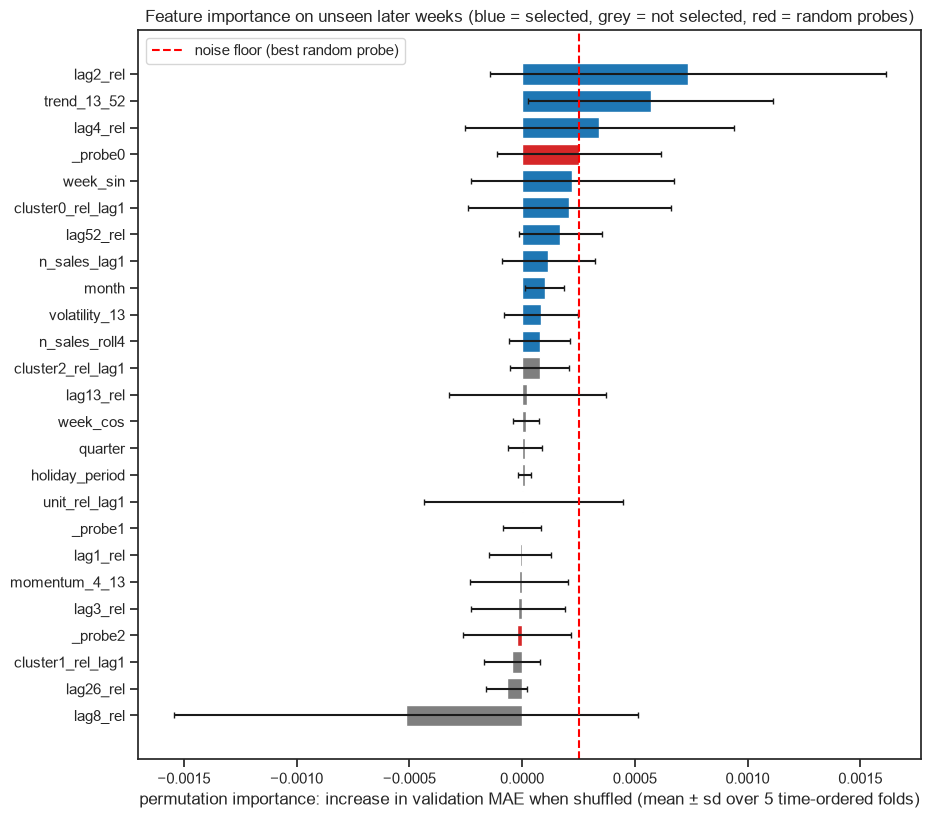

In [29]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import TimeSeriesSplit

rng = np.random.default_rng(RANDOM_STATE)
PROBES = [f"_probe{i}" for i in range(3)]
X_sel = train_F[FEATURES].copy()
for c in PROBES:
    X_sel[c] = rng.normal(size=len(X_sel))
y_sel = train_F[TARGET]

fold_imp = []
for k, (tr_idx, va_idx) in enumerate(TimeSeriesSplit(n_splits=5).split(X_sel)):
    rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, max_features=0.5, random_state=RANDOM_STATE, n_jobs=-1)
    rf.fit(X_sel.iloc[tr_idx], y_sel.iloc[tr_idx])
    pi = permutation_importance(rf, X_sel.iloc[va_idx], y_sel.iloc[va_idx], scoring="neg_mean_absolute_error",
                                n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
    fold_imp.append(pd.Series(pi.importances_mean, index=X_sel.columns, name=f"fold {k + 1}"))
imp = pd.concat(fold_imp, axis=1)
imp_mean, imp_std = imp.mean(axis=1), imp.std(axis=1)
NOISE_FLOOR = max(imp_mean[PROBES].max(), 0)
importance = imp_mean.drop(PROBES).sort_values(ascending=False)

corr = train_F[FEATURES].corr().abs()
redundant = set()
for i, a in enumerate(FEATURES):
    for b in FEATURES[i + 1:]:
        if corr.loc[a, b] > 0.95 and a not in redundant and b not in redundant:
            redundant.add(a if importance[a] < importance[b] else b)
ranked = [f for f in importance.index if f not in redundant]
above_noise = [f for f in ranked if importance[f] > NOISE_FLOOR]
print(f"Noise floor (best random probe): {NOISE_FLOOR:.5f}  (MAE units of the relative target)")
print("Redundant:", sorted(redundant))
print(f"Above the noise floor ({len(above_noise)}):", above_noise)


def ts_cv_mae(cols):
    errs = []
    for tr_idx, va_idx in TimeSeriesSplit(n_splits=5).split(train_F):
        m = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, max_features=0.5, random_state=RANDOM_STATE, n_jobs=-1)
        m.fit(train_F[cols].iloc[tr_idx], y_sel.iloc[tr_idx])
        errs.append(mean_absolute_error(y_sel.iloc[va_idx], m.predict(train_F[cols].iloc[va_idx])))
    return np.mean(errs), np.std(errs)


candidates = {"all features (minus redundant)": ranked, "above noise floor": above_noise,
              "top 10 by importance": ranked[:10], "top 5 by importance": ranked[:5]}
cand_res = pd.DataFrame({name: dict(zip(["CV MAE", "CV MAE sd"], ts_cv_mae(cols)), n_features=len(cols))
                         for name, cols in candidates.items() if cols}).T.sort_values("CV MAE")
cand_res.loc["(MA-13 = predict 0)", ["CV MAE", "n_features"]] = [
    np.mean([y_sel.iloc[va].abs().mean() for _, va in TimeSeriesSplit(n_splits=5).split(train_F)]), 0]
display(cand_res.style.format({"CV MAE": "{:.5f}", "CV MAE sd": "{:.5f}", "n_features": "{:.0f}"}))
BEST_SET = cand_res.drop("(MA-13 = predict 0)").index[0]
selected_features = candidates[BEST_SET]
print(f"Selected: {BEST_SET} -> {len(selected_features)} features:", selected_features)

order = imp_mean.sort_values().index
fig, ax = plt.subplots(figsize=(9, 9))
ax.barh(order, imp_mean[order], xerr=imp_std[order], capsize=2,
        color=["tab:red" if f in PROBES else ("tab:blue" if f in selected_features else "tab:gray") for f in order])
ax.axvline(NOISE_FLOOR, color="red", ls="--", label="noise floor (best random probe)")
ax.set_xlabel("permutation importance: increase in validation MAE when shuffled (mean ± sd over 5 time-ordered folds)")
ax.set_title("Feature importance on unseen later weeks (blue = selected, grey = not selected, red = random probes)")
ax.legend()
plt.show()

**Reading this result.** Individual importances are tiny. A change in validation MAE of 0.0005 is about 0.05 percentage points of price, and most features don't beat random noise consistently across folds. Even last week's price (`lag1_rel`) adds nothing once the 13-week average is the reference point. That is a genuine finding about this series: weekly median prices are mostly noise around a slowly moving trend, so *any* single feature's contribution is small, and a hard cut-off on such noisy importances throws away useful signal. The candidate comparison picks the set that forecasts best on later weeks instead.

> ✍️ **Your observations (feature selection):** which features carry the signal (trend, lags, seasonality, volume)? How small is the gain over predicting 0, which is what the MA-13 baseline does?

## 13. Modeling
### 13.1 Naive forecasting baselines
For weekly prices, simple baselines are hard to beat, so they set the bar:
* **Naive**: next week = last week
* **MA-4 / MA-13**: mean of the last 4 or 13 weeks (MA-13 is exactly $\hat y^{rel}=0$)
* **Seasonal naive**: same week last year, scaled by the trend

Every model is scored on **observed** test weeks only. Imputed weeks are excluded, because their "truth" is itself an estimate.

In [30]:
ev = test_F[test_F["_observed"]]
actual = ev["_actual"]


def score(name, pred):
    pred = pd.Series(pred, index=ev.index)
    return {"model": name, "MAE ($)": mean_absolute_error(actual, pred),
            "RMSE ($)": np.sqrt(mean_squared_error(actual, pred)),
            "MAPE (%)": (np.abs(actual - pred) / actual).mean() * 100}


results, preds = [], {}
p_all = weekly["price_clean"]
preds["Naive (last week)"] = p_all.shift(1).loc[ev.index]
preds["MA-4"] = p_all.shift(1).rolling(4).mean().loc[ev.index]
preds["MA-13"] = ev["_base"]
preds["Seasonal naive (52w, trend-adjusted)"] = (p_all.shift(52) * (p_all.shift(1).rolling(13).mean() / p_all.shift(53).rolling(13).mean())).loc[ev.index]
for k, v in preds.items():
    results.append(score(f"Baseline: {k}", v))
pd.DataFrame(results).set_index("model").round(2)

,MAE ($),RMSE ($),MAPE (%)
model,,,
Baseline: Naive (last week),36129.09,45072.58,5.43
Baseline: MA-4,31067.95,40317.63,4.66
Baseline: MA-13,30597.06,38016.69,4.58
"Baseline: Seasonal naive (52w, trend-adjusted)",35838.66,46019.76,5.37


### 13.2 AutoViML (regression)
Same four model families as the tabular notebook (`Boosting_Flag` = `None` linear, `False` random forest, `True` XGBoost, `"CatBoost"`), plus the extra ensemble members each run trains. AutoViML predicts $\hat y^{rel}$, which is converted back to dollars with $\hat P_t = \bar P_{t-13..t-1}(1+\hat y^{rel}_t)$.

**Caveat:** AutoViML's internal validation uses its own (non-chronological) folds. That is why the **honest** evaluation here is the untouched, chronologically later test period.

Imported Auto_ViML version: 0.2.02. Call using:
             m, feats, trainm, testm = Auto_ViML(train, target, test,
                            sample_submission='',
                            scoring_parameter='', KMeans_Featurizer=False,
                            hyper_param='RS',feature_reduction=True,
                             Boosting_Flag='CatBoost', Binning_Flag=False,
                            Add_Poly=0, Stacking_Flag=False,Imbalanced_Flag=False,
                            GPU_flag=False, verbose=1)
            

Imported Auto_NLP version: 0.1.01.. Call using:
     train_nlp, test_nlp, nlp_pipeline, predictions = Auto_NLP(
                nlp_column, train, test, target, score_type='balanced_accuracy',
                modeltype='Classification',top_num_features=200, verbose=0,
                build_model=True)

============================== AutoViML: Linear (Boosting_Flag=None) ==============================
##############  D A T A   S E T  A N A L Y S I S  #######

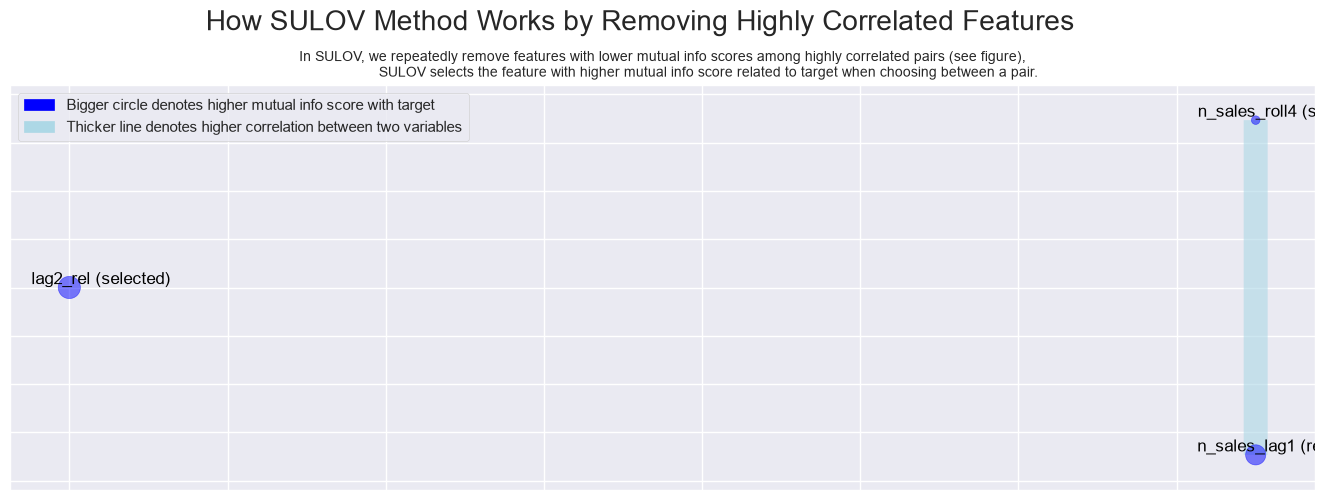

Splitting selected features into float and categorical (integer) variables:
    (8) float variables ...
    (1) categorical vars...
###############################################################################
#######     F E A T U R E   S E L E C T I O N    BY   X G B O O S T    ########
###############################################################################
Current number of predictors = 9 
    Finding Important Features using Boosted Trees algorithm...
        using 9 variables...
        using 7 variables...
        using 5 variables...
        using 3 variables...
Found 9 important features
    Performing limited feature engineering for binning, add_poly and KMeans_Featurizer flags  ...
    Train CV Split completed with TRAIN rows =  361 , CV rows =  41
    Binning_Flag set to False or there are no float vars in data set to be binned
    KMeans_Featurizer set to False or there are no float variables in data
Performing MinMax scaling of train and validation data
#########

    Actual training time (in seconds): 2
###########  Single_Label  M O D E L   R E S U L T S #################
5-fold Cross Validation rmse Score = 0.0603
    Best Parameters for Model = {'C': 23.504378152453466, 'epsilon': 0.0065530026811640996}
########################################################
Linear Model Prediction Results on Held Out CV Data Set:
Regression Plots completed in 0.010 seconds
    MAE = 0.0539
    MAPE = 128% (MAPE will be very high when zeros in actuals)
    RMSE = 0.0640
    Normalized MAE (as % std dev of Actuals) = 144%
    Normalized RMSE (% of Std Dev of Actuals) = 97%
################# E N S E M B L E  M O D E L  ##################
Time taken = 0 seconds
Based on trying multiple models, Best type of algorithm for this data set is Bagging_Regressor
    Displaying results of weighted average ensemble of 5 regressors
#############################################################################
Regression Plots completed in 0.006 seconds
    MAE = 0.0527
  

    Calculating weighted average ensemble of 5 regressors
Completed Ensemble predictions on held out data
    Plotting Feature Importances to explain the output of model
############### P R E D I C T I O N  O N  T E S T   C O M P L E T E D  #################
    Time taken thus far (in seconds) = 2
Writing Output files to disk...
    Saving predictions to ./y_rel/y_rel_Regression_test_modified.csv
    Saving predictions to ./y_rel/y_rel_Regression_submission.csv
    Saving predictions to ./y_rel/y_rel_Regression_train_modified.csv
###############  C O M P L E T E D  ################
Time Taken in mins = 0.0 for the Entire Process

============================== AutoViML: RandomForest (Boosting_Flag=False) ==============================
##############  D A T A   S E T  A N A L Y S I S  #######################
Training Set Shape = (402, 11)
    Training Set Memory Usage = 0.03 MB
Test Set Shape = (114, 10)
    Test Set Memory Usage = 0.01 MB
Single_Label Target: ['y_rel']

##############

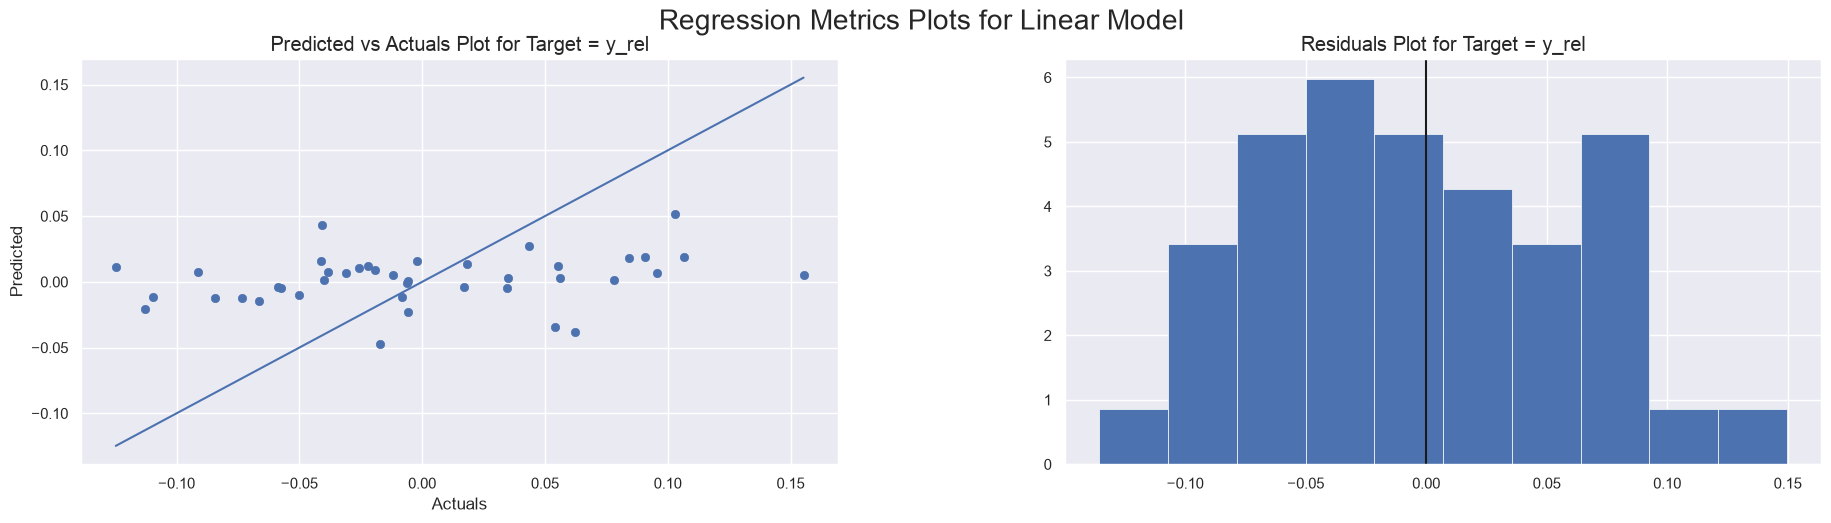

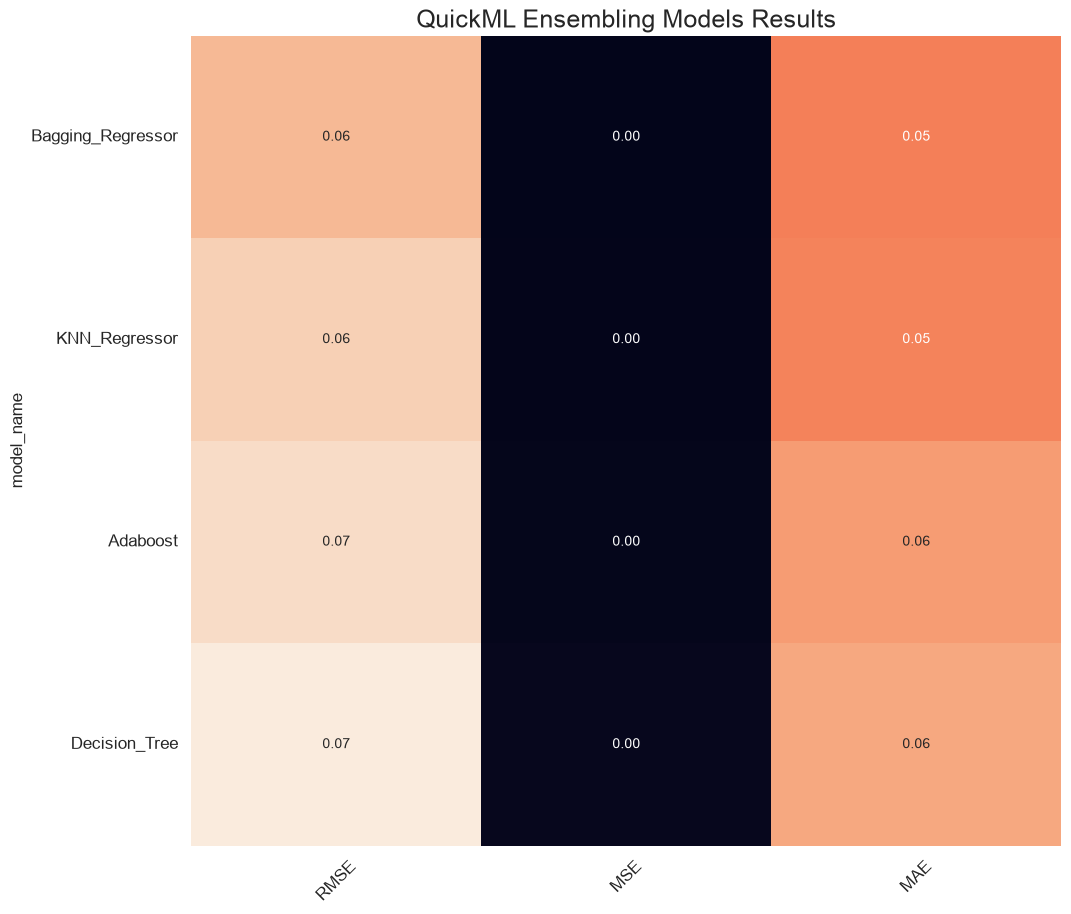

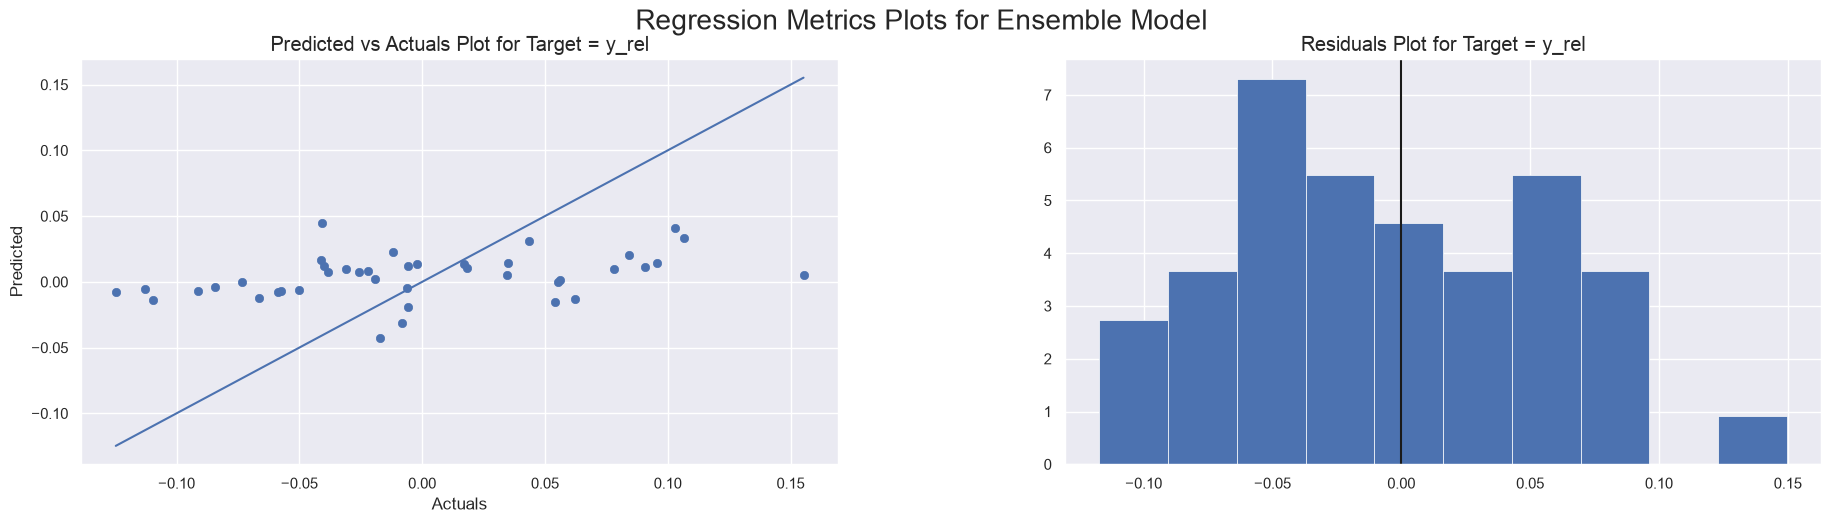

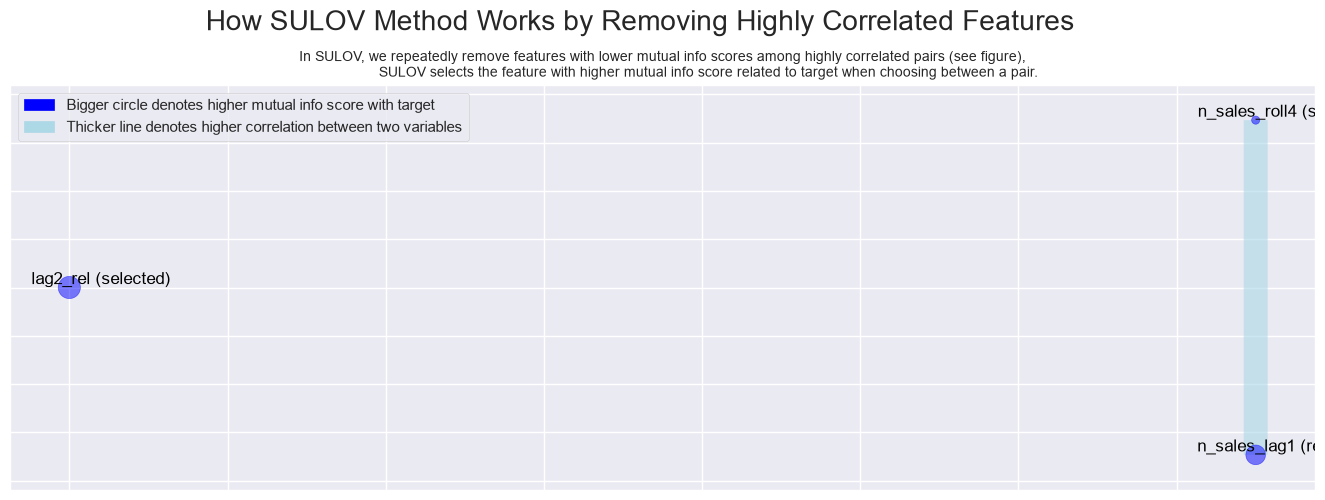

Splitting selected features into float and categorical (integer) variables:
    (8) float variables ...
    (1) categorical vars...
###############################################################################
#######     F E A T U R E   S E L E C T I O N    BY   X G B O O S T    ########
###############################################################################
Current number of predictors = 9 
    Finding Important Features using Boosted Trees algorithm...
        using 9 variables...
        using 7 variables...
        using 5 variables...
        using 3 variables...
Found 9 important features
    Performing limited feature engineering for binning, add_poly and KMeans_Featurizer flags  ...
    Train CV Split completed with TRAIN rows =  361 , CV rows =  41
    Binning_Flag set to False or there are no float vars in data set to be binned
    KMeans_Featurizer set to False or there are no float variables in data
Performing MinMax scaling of train and validation data
#########

    Actual training time (in seconds): 6
###########  Single_Label  M O D E L   R E S U L T S #################
5-fold Cross Validation rmse Score = 0.0602
    Best Parameters for Model = {'max_depth': 4, 'min_samples_leaf': 5, 'n_estimators': 285}
########################################################
Forests Model Prediction Results on Held Out CV Data Set:
Regression Plots completed in 0.008 seconds
    MAE = 0.0459
    MAPE = 270% (MAPE will be very high when zeros in actuals)
    RMSE = 0.0570
    Normalized MAE (as % std dev of Actuals) = 115%
    Normalized RMSE (% of Std Dev of Actuals) = 90%
################# E N S E M B L E  M O D E L  ##################
Time taken = 0 seconds
Based on trying multiple models, Best type of algorithm for this data set is Linear_SVR
    Displaying results of weighted average ensemble of 5 regressors
#############################################################################
Regression Plots completed in 0.007 seconds
    MAE = 0.0461
    MAP

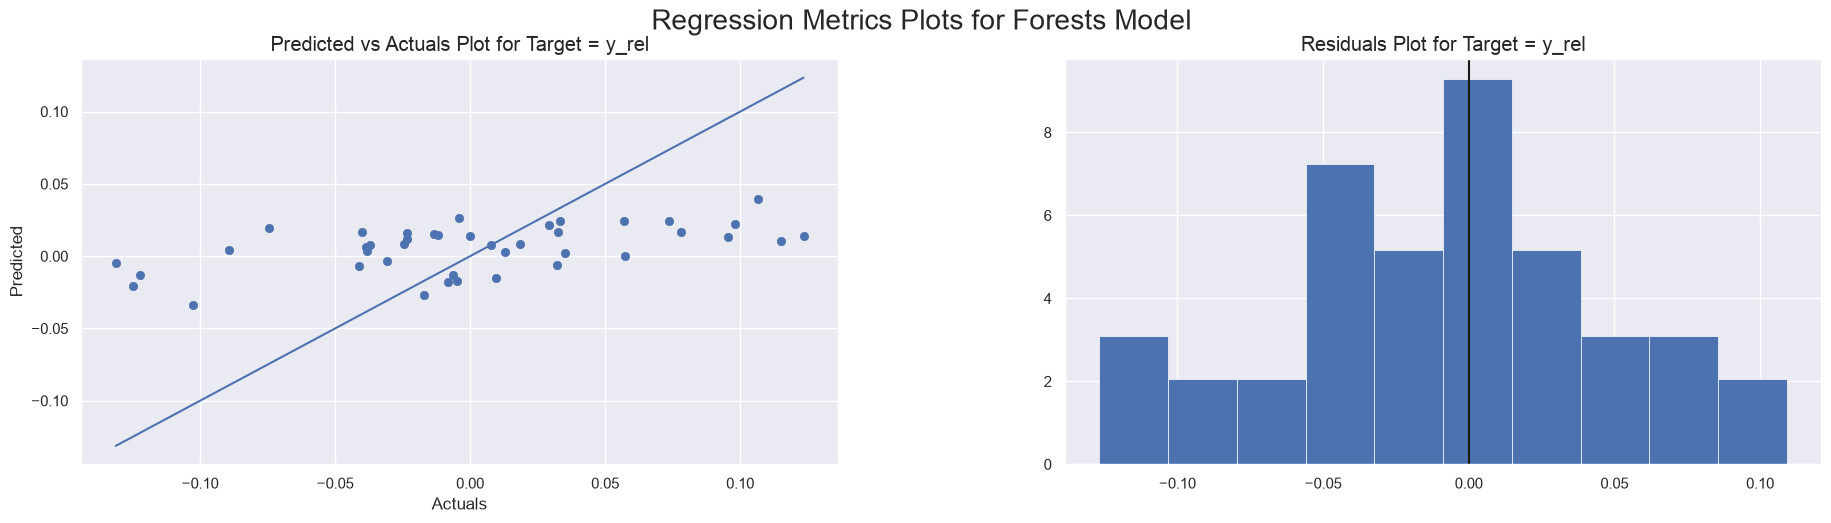

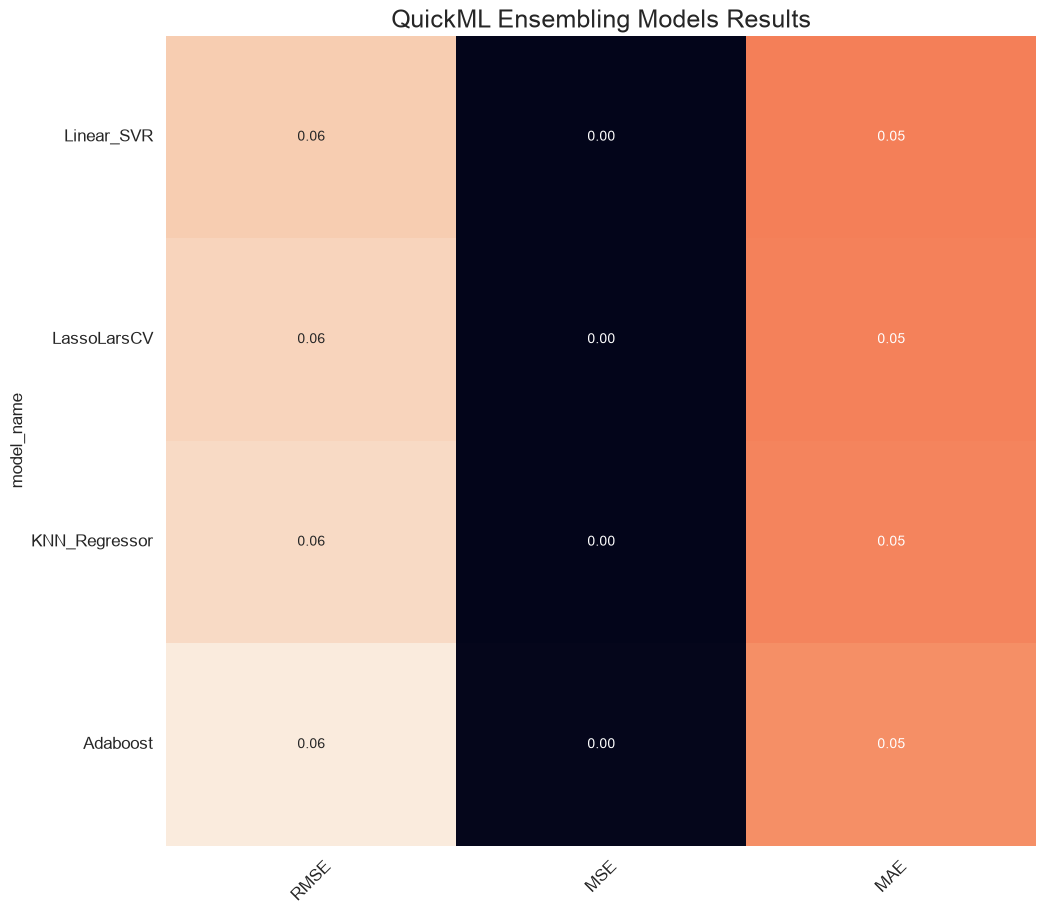

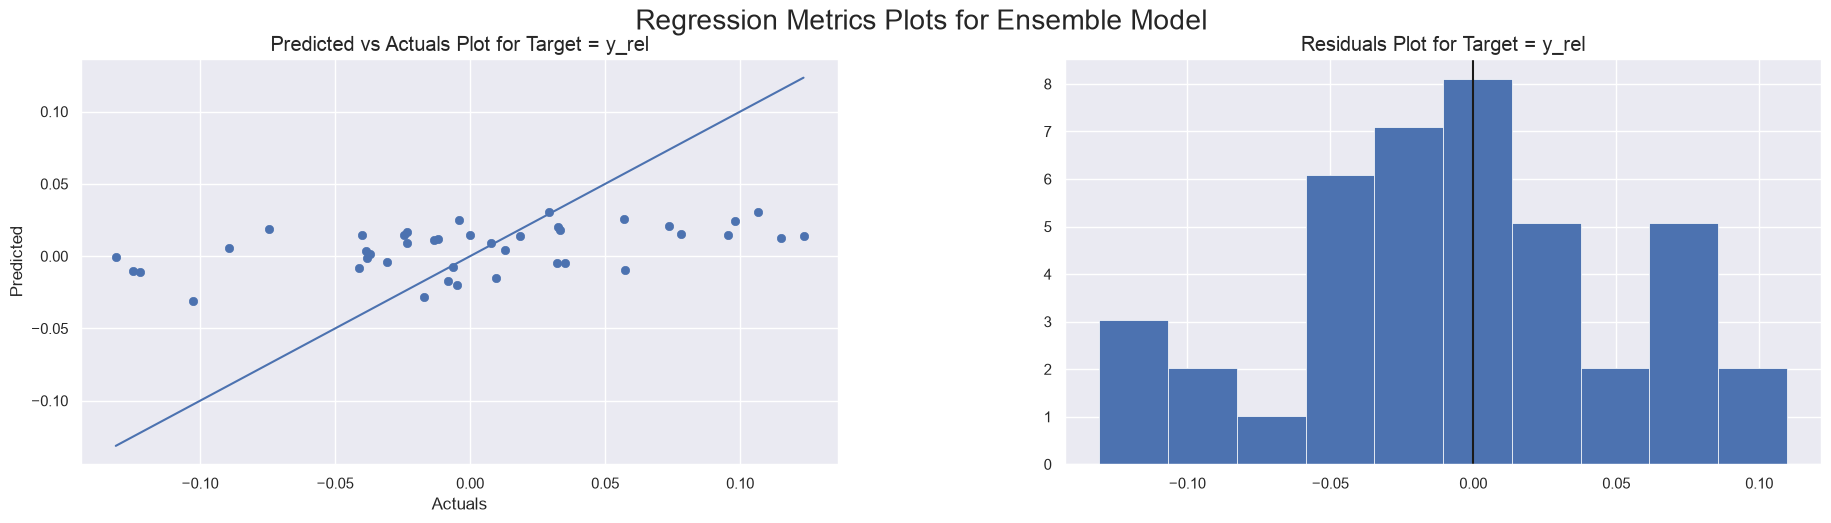

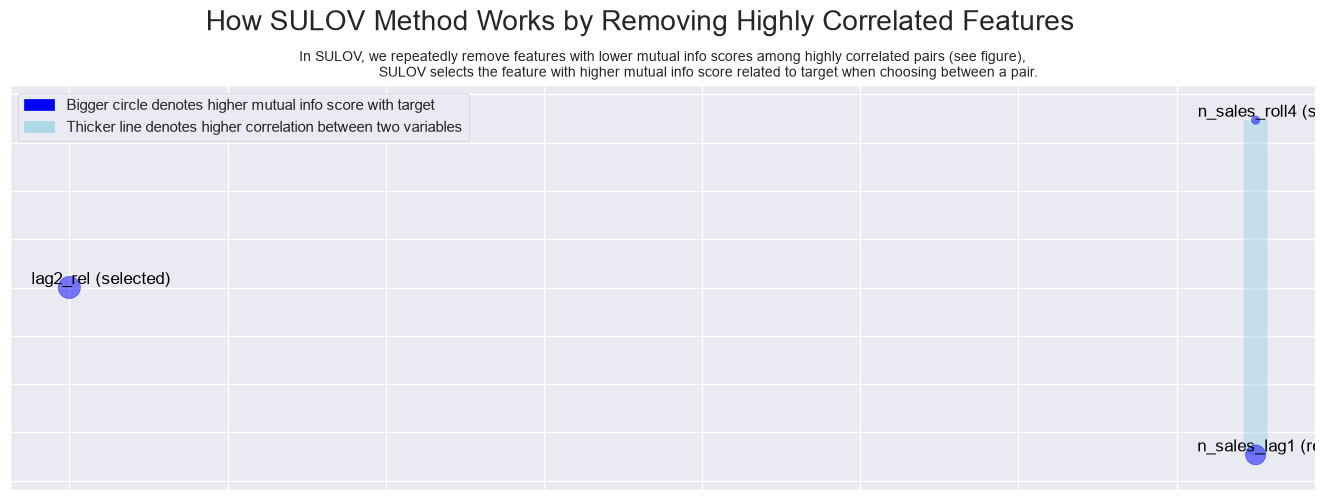

Splitting selected features into float and categorical (integer) variables:
    (8) float variables ...
    (1) categorical vars...
###############################################################################
#######     F E A T U R E   S E L E C T I O N    BY   X G B O O S T    ########
###############################################################################
Current number of predictors = 9 
    Finding Important Features using Boosted Trees algorithm...
        using 9 variables...
        using 7 variables...
        using 5 variables...
        using 3 variables...
Found 9 important features
    Performing limited feature engineering for binning, add_poly and KMeans_Featurizer flags  ...
    Train CV Split completed with TRAIN rows =  361 , CV rows =  41
    Binning_Flag set to False or there are no float vars in data set to be binned
    KMeans_Featurizer set to False or there are no float variables in data
Performing MinMax scaling of train and validation data
#########

    Actual training time (in seconds): 0
###########  Single_Label  M O D E L   R E S U L T S #################
5-fold Cross Validation rmse Score = 0.0598
    Best Parameters for Model = {'gamma': 16, 'learning_rate': 0.3382826838838474, 'max_depth': 3, 'n_estimators': 294}
########################################################
XGBoost Model Prediction Results on Held Out CV Data Set:
Regression Plots completed in 0.007 seconds
    MAE = 0.0501
    MAPE = 240% (MAPE will be very high when zeros in actuals)
    RMSE = 0.0601
    Normalized MAE (as % std dev of Actuals) = 127%
    Normalized RMSE (% of Std Dev of Actuals) = 92%
################# E N S E M B L E  M O D E L  ##################
Time taken = 0 seconds
Based on trying multiple models, Best type of algorithm for this data set is RF_Regressor
    Displaying results of weighted average ensemble of 5 regressors
#############################################################################
Regression Plots completed in 0.007 sec

Training Set Shape = (402, 11)
    Training Set Memory Usage = 0.03 MB
Test Set Shape = (114, 10)
    Test Set Memory Usage = 0.01 MB
Single_Label Target: ['y_rel']

################ Regression VISUALIZATION Started #####################
No shuffling of data set before training...
    Using RandomizedSearchCV for Hyper Parameter Tuning. This is 3X faster than GridSearchCV...
#######################################################################################
######################## C L A S S I F Y I N G  V A R I A B L E S  ####################
#######################################################################################
Classifying variables in data set...
    10 Predictors classified...
    No variables removed since no ID or low-information variables found in data set
##############################################################################
######     D A T A    P R E P A R A T I O N   AND C L E A N I N G     ########
###############################################

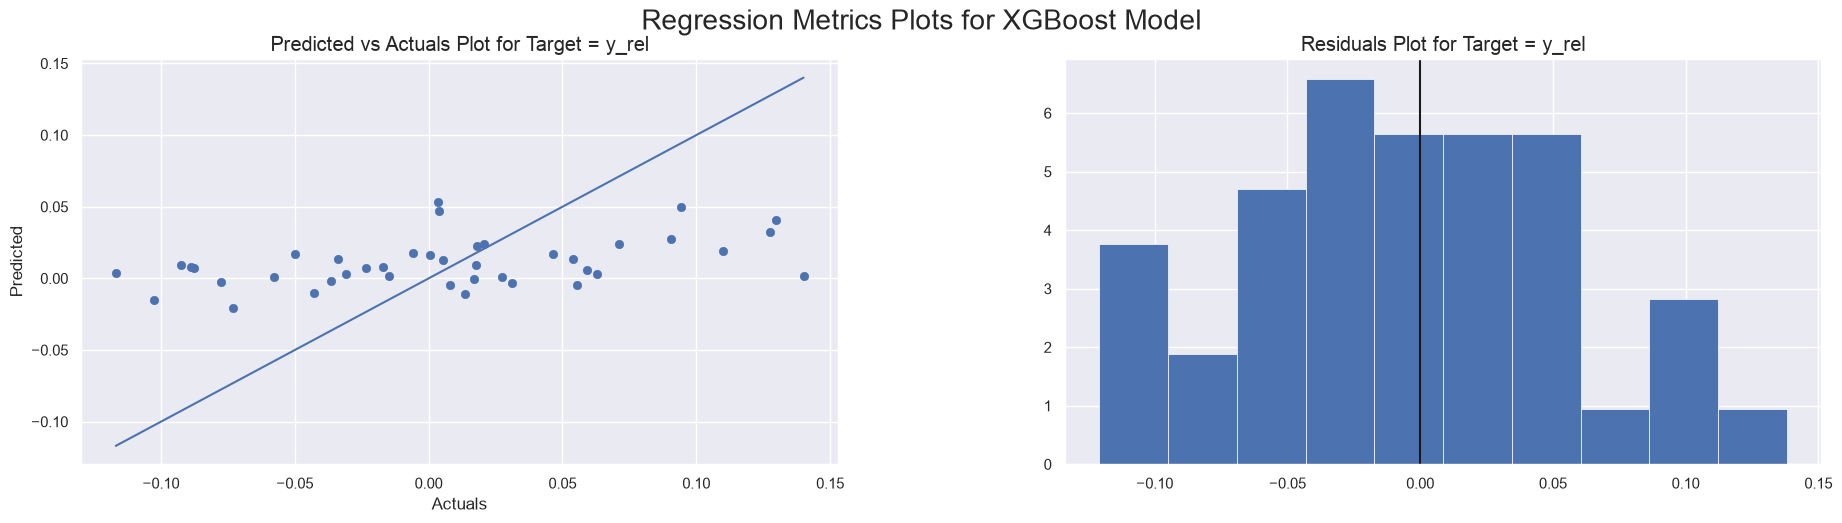

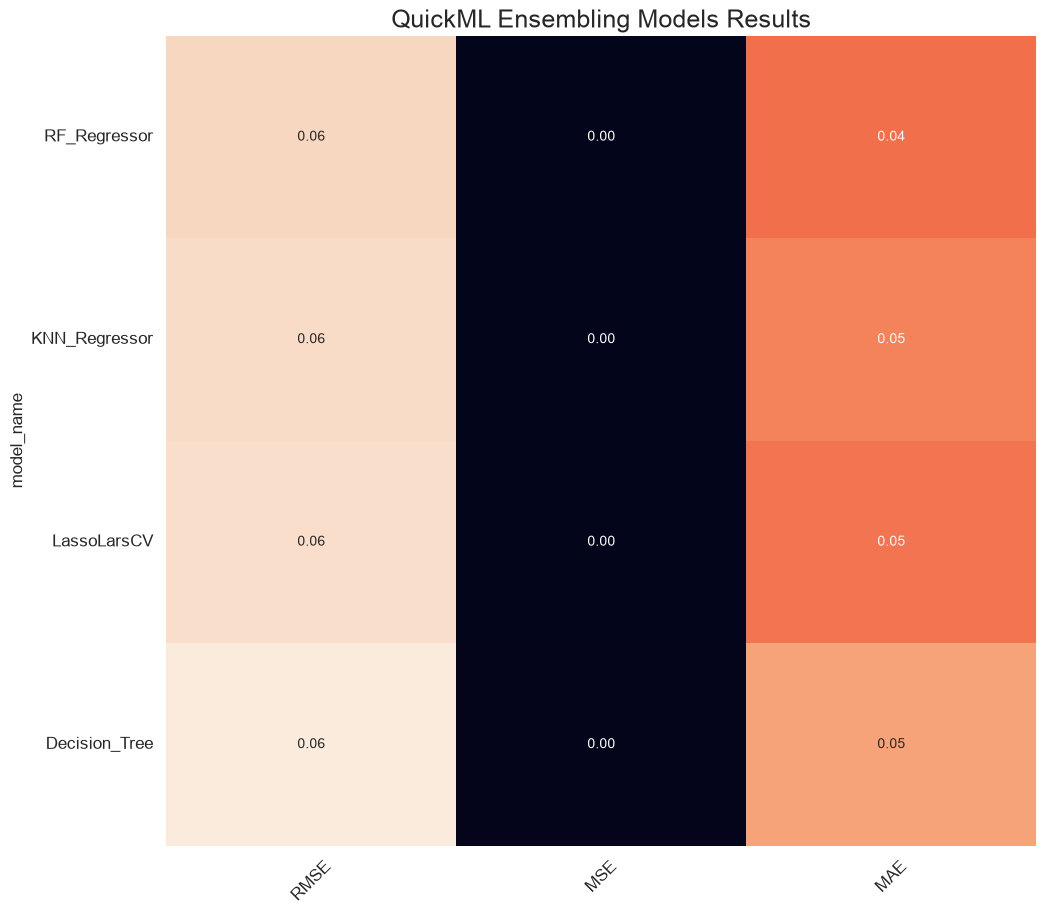

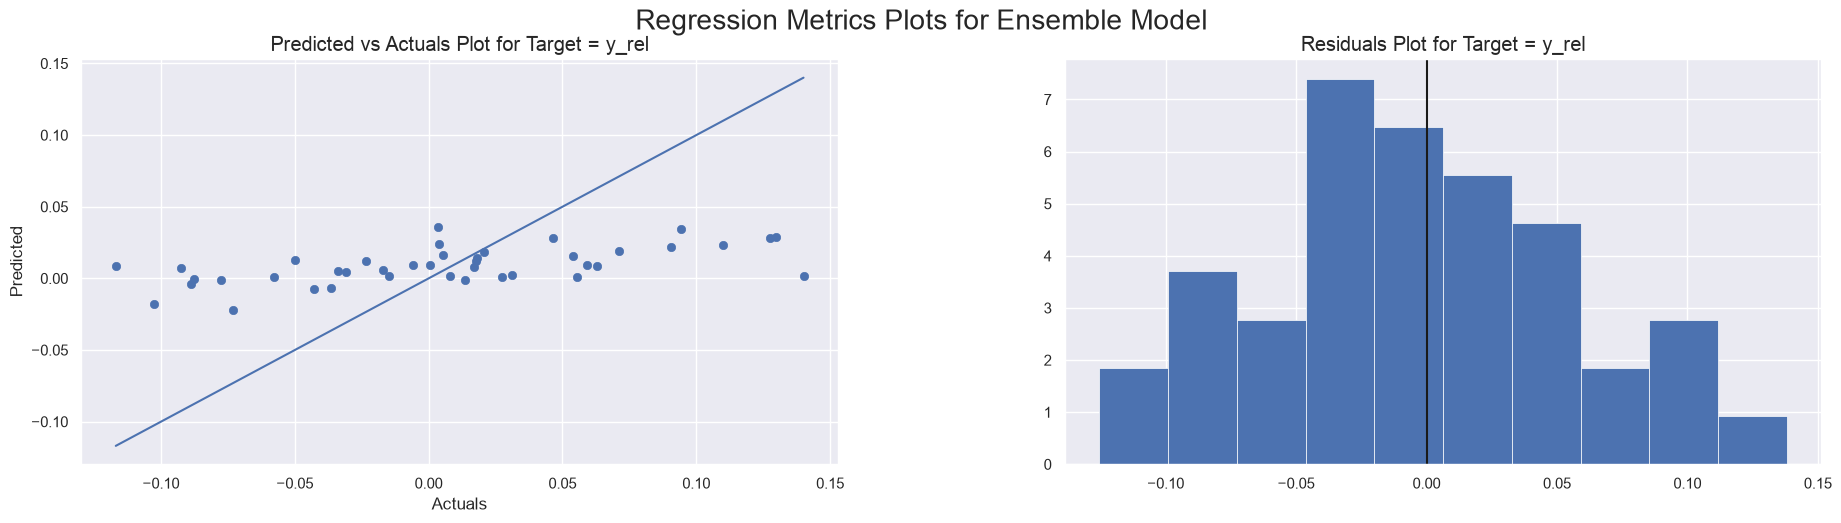

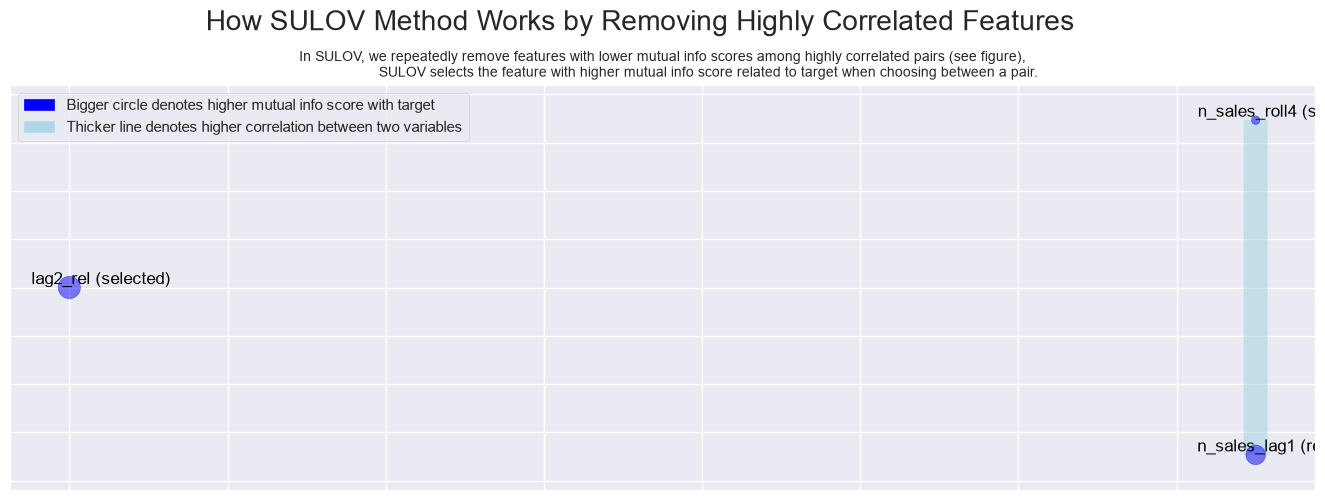

Splitting selected features into float and categorical (integer) variables:
    (8) float variables ...
    (1) categorical vars...
###############################################################################
#######     F E A T U R E   S E L E C T I O N    BY   X G B O O S T    ########
###############################################################################
Current number of predictors = 9 
    Finding Important Features using Boosted Trees algorithm...
        using 9 variables...
        using 7 variables...
        using 5 variables...
        using 3 variables...
Found 9 important features
    Performing limited feature engineering for binning, add_poly and KMeans_Featurizer flags  ...
    Train CV Split completed with TRAIN rows =  361 , CV rows =  41
    Binning_Flag set to False or there are no float vars in data set to be binned
    KMeans_Featurizer set to False or there are no float variables in data
Skipping MinMax scaling since perform_scaling flag is set to Fal

MetricVisualizer(layout=Layout(align_self='stretch', height='500px'))

Learning rate set to 0.022201
0:	learn: 0.0610076	test: 0.0682804	best: 0.0682804 (0)	total: 57.5ms	remaining: 2m 52s


500:	learn: 0.0304466	test: 0.0674542	best: 0.0652171 (116)	total: 193ms	remaining: 962ms
1000:	learn: 0.0160386	test: 0.0706513	best: 0.0652171 (116)	total: 333ms	remaining: 664ms


1500:	learn: 0.0089772	test: 0.0718464	best: 0.0652171 (116)	total: 470ms	remaining: 469ms
2000:	learn: 0.0051988	test: 0.0722051	best: 0.0652171 (116)	total: 600ms	remaining: 299ms
Stopped by overfitting detector  (2000 iterations wait)

bestTest = 0.06521709128
bestIteration = 116

Shrink model to first 117 iterations.
    Actual training time (in seconds): 1
###########  Single_Label  M O D E L   R E S U L T S #################
5-fold Cross Validation RMSE Score = 0.0652
    CatBoost Best Parameters for Model: Iterations = 116, learning_rate = 0.02
########################################################
CatBoost Model Prediction Results on Held Out CV Data Set:
Regression Plots completed in 0.007 seconds
    MAE = 0.0524
    MAPE = 158% (MAPE will be very high when zeros in actuals)
    RMSE = 0.0652
    Normalized MAE (as % std dev of Actuals) = 127%
    Normalized RMSE (% of Std Dev of Actuals) = 95%
################# E N S E M B L E  M O D E L  ##################


Time taken = 0 seconds
Based on trying multiple models, Best type of algorithm for this data set is LassoLarsCV
    Displaying results of weighted average ensemble of 5 regressors
#############################################################################
Regression Plots completed in 0.007 seconds
    MAE = 0.0526
    MAPE = 158% (MAPE will be very high when zeros in actuals)
    RMSE = 0.0657
    Normalized MAE (as % std dev of Actuals) = 127%
    Normalized RMSE (% of Std Dev of Actuals) = 96%
After multiple models, Ensemble Model Results:
    RMSE Score = 0.06571
#############################################################################
Single Model is better than Ensembling Models for this data set.
    Time taken for this Target (in seconds) = 1
    Binning_Flag set to False or there are no float vars in data set to be binned
    Setting best params for CatBoost model from Initial State since you cannot change params to a fitted Catboost model 
    Number of Categorical and 

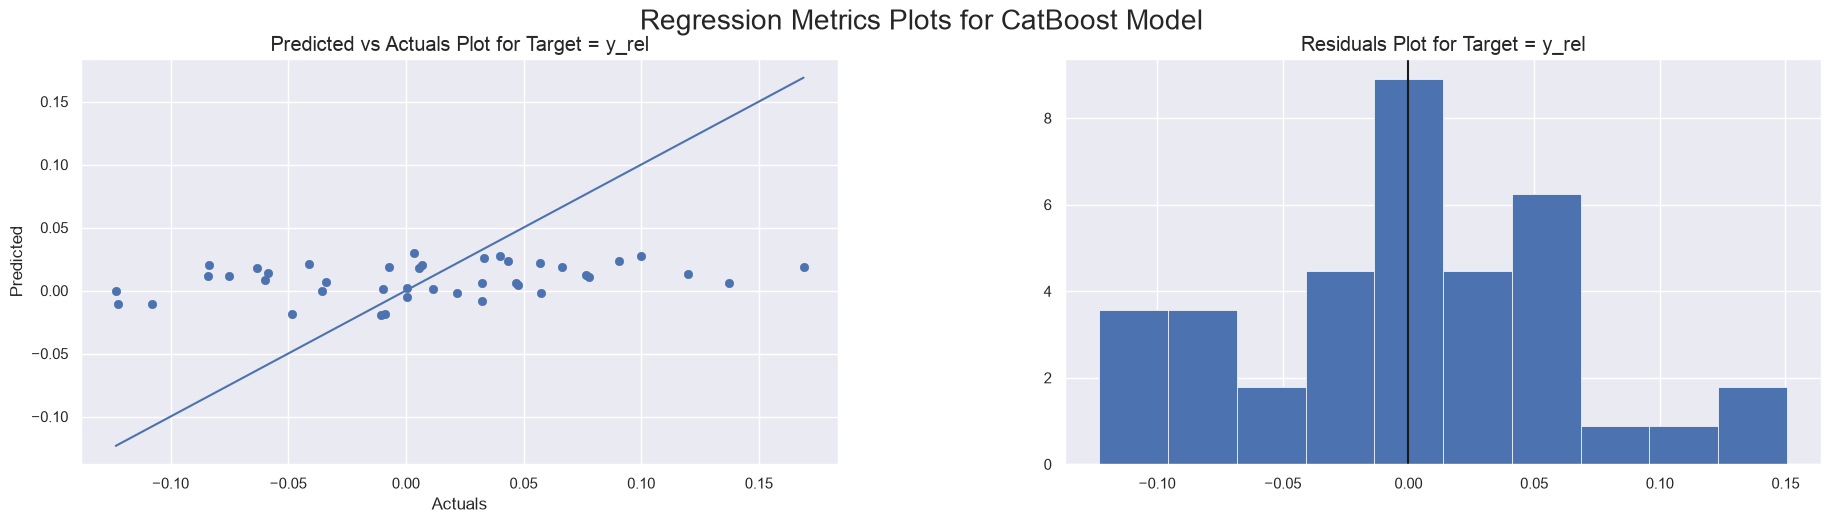

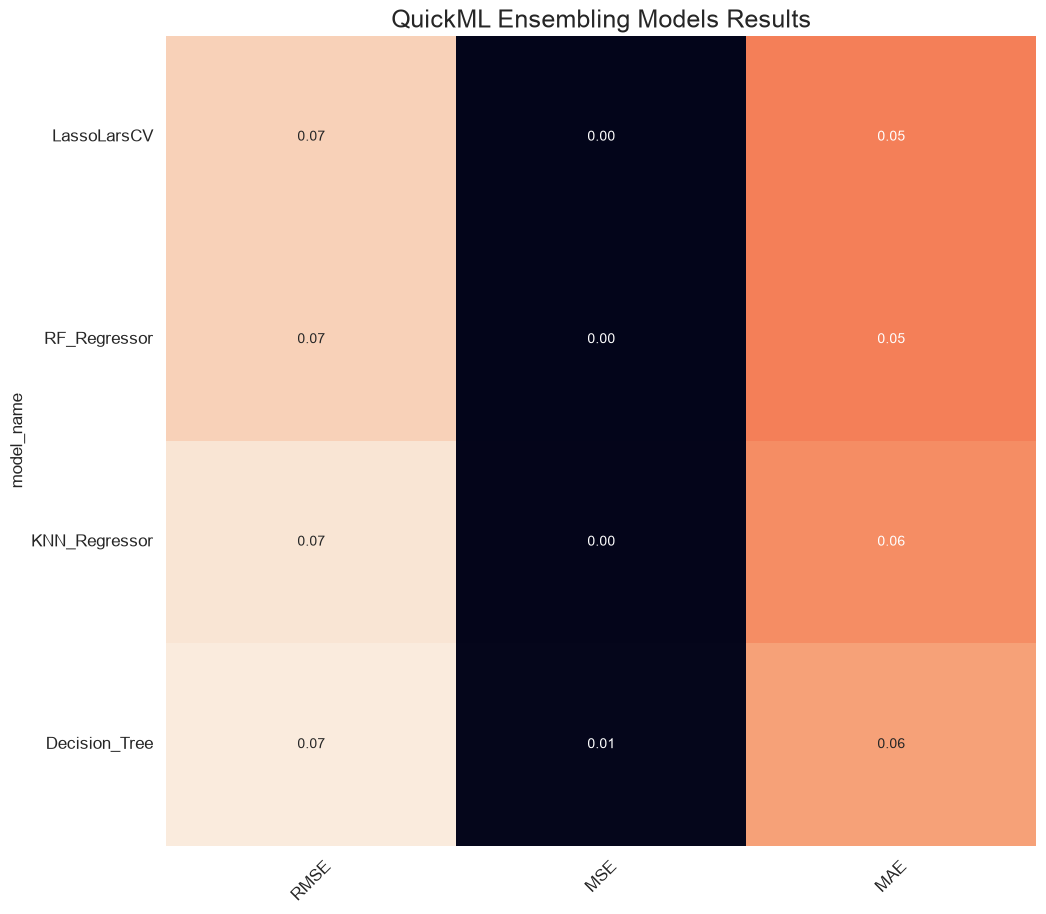

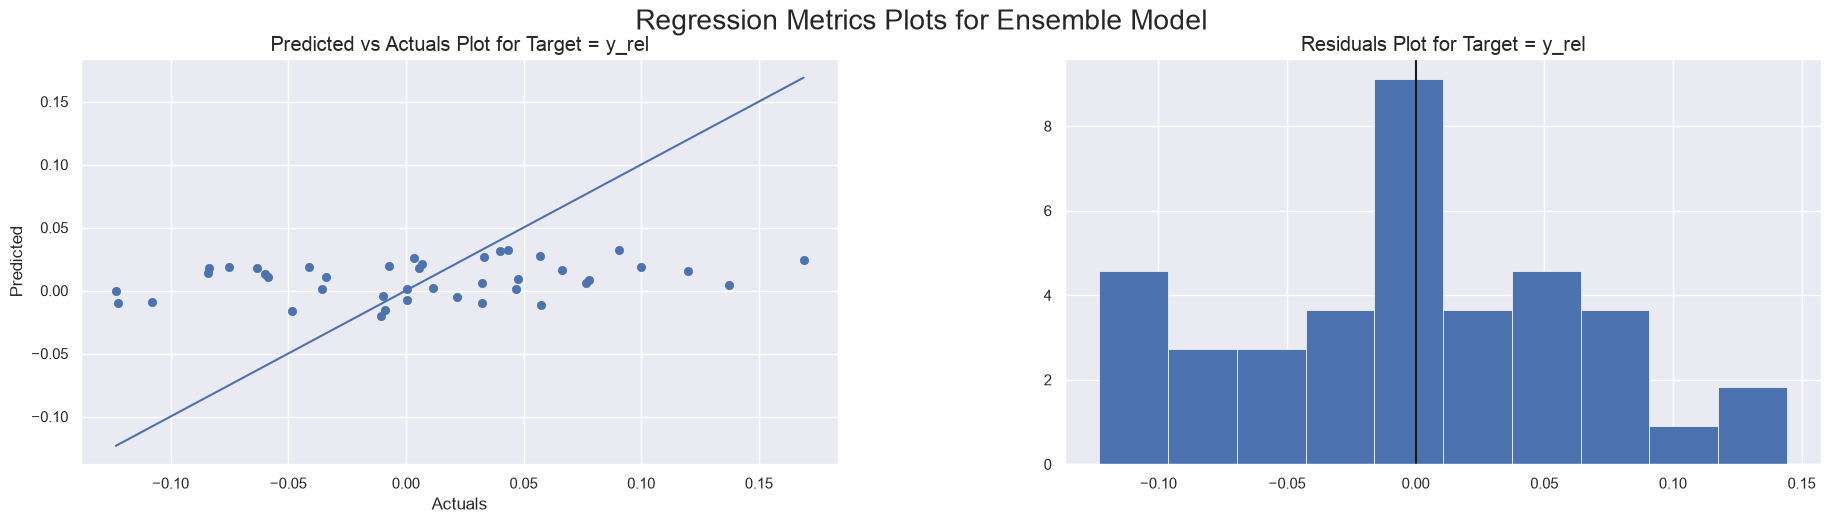

In [31]:
from autoviml.Auto_ViML import Auto_ViML

AVML_CONFIGS = {"Linear": None, "RandomForest": False, "XGBoost": True, "CatBoost": "CatBoost"}
avml_train = train_F[selected_features + [TARGET]].reset_index(drop=True)
avml_test = test_F[selected_features].reset_index(drop=True)
avml_runs, seen = {}, set()
ev_mask = test_F["_observed"].values

for name, flag in AVML_CONFIGS.items():
    print(f"\n{'=' * 30} AutoViML: {name} (Boosting_Flag={flag!r}) {'=' * 30}")
    model, feats, trainm, testm = Auto_ViML(
        avml_train.copy(), TARGET, avml_test.copy(), sample_submission="",
        hyper_param="RS", feature_reduction=True, scoring_parameter="",
        Boosting_Flag=flag, KMeans_Featurizer=False, Binning_Flag=False, Add_Poly=0,
        Stacking_Flag=False, Imbalanced_Flag=False, verbose=0)
    avml_runs[name] = {"model": model, "features": feats, "testm": testm}
    main_col = f"{TARGET}_predictions"
    for col in testm.columns:
        if not col.endswith("_predictions"):
            continue
        if col != main_col and testm[col].equals(testm[main_col]):
            continue
        sub = col[len(TARGET) + 1:-len("_predictions")]
        label = f"AutoViML {name}" if col == main_col else (
            f"AutoViML {name} → Ensemble" if sub == "Ensembled" else f"AutoViML ensemble member: {sub}")
        if label in seen:
            continue
        seen.add(label)
        price_hat = test_F["_base"].values * (1 + testm[col].values)
        preds[label] = pd.Series(price_hat[ev_mask], index=ev.index)
        results.append(score(label, preds[label]))

## 14. Results

,MAE ($),RMSE ($),MAPE (%)
model,,,
AutoViML ensemble member: Linear_SVR,"28,282","36,826",4.24
AutoViML CatBoost → Ensemble,"28,382","36,637",4.28
AutoViML CatBoost,"28,684","36,634",4.32
AutoViML RandomForest → Ensemble,"28,704","36,773",4.32
AutoViML ensemble member: LassoLarsCV,"28,826","37,256",4.34
AutoViML RandomForest,"28,870","36,747",4.35
AutoViML ensemble member: RF_Regressor,"28,881","37,363",4.35
AutoViML Linear → Ensemble,"29,629","38,065",4.49
AutoViML XGBoost → Ensemble,"29,951","37,674",4.50


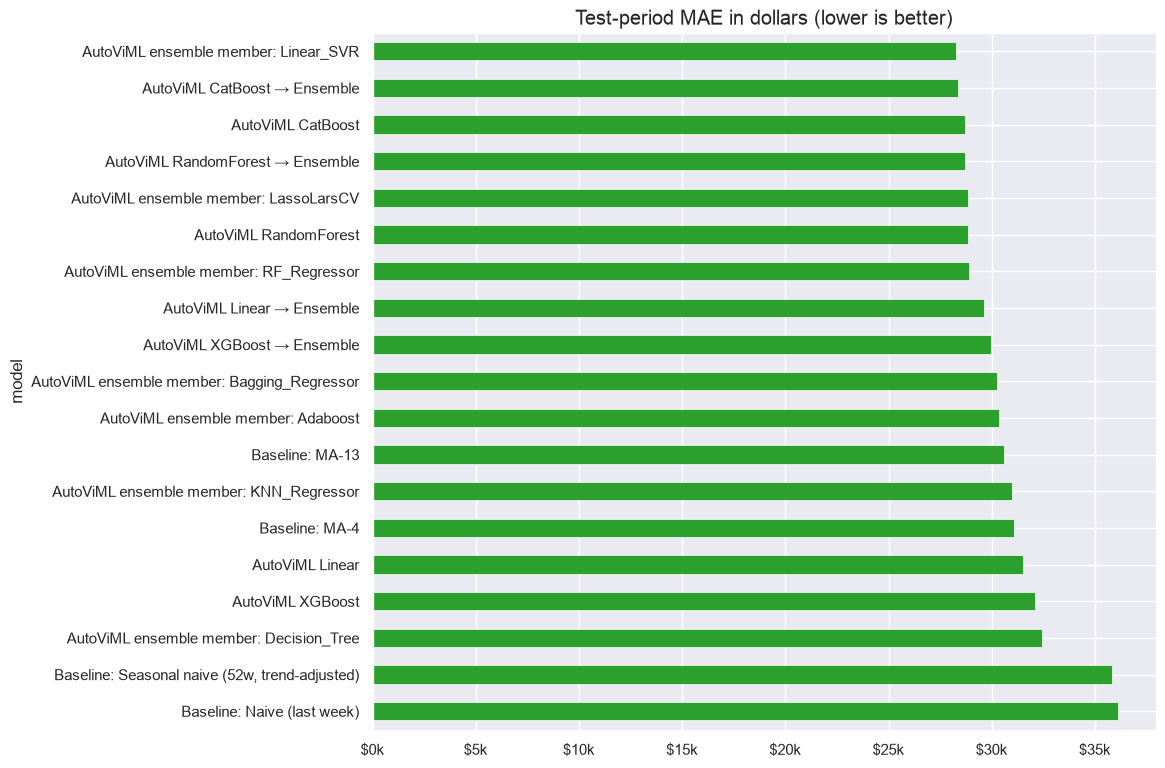

In [32]:
res = pd.DataFrame(results).set_index("model").sort_values("MAE ($)")
display(res.style.format({"MAE ($)": "{:,.0f}", "RMSE ($)": "{:,.0f}", "MAPE (%)": "{:.2f}"})
        .background_gradient(cmap="Greens_r", subset=["MAE ($)", "MAPE (%)"]))
res["MAE ($)"].sort_values(ascending=False).plot.barh(figsize=(9, 0.4 * len(res) + 1), color="tab:green")
plt.title("Test-period MAE in dollars (lower is better)")
plt.gca().xaxis.set_major_formatter(dollars)
plt.show()

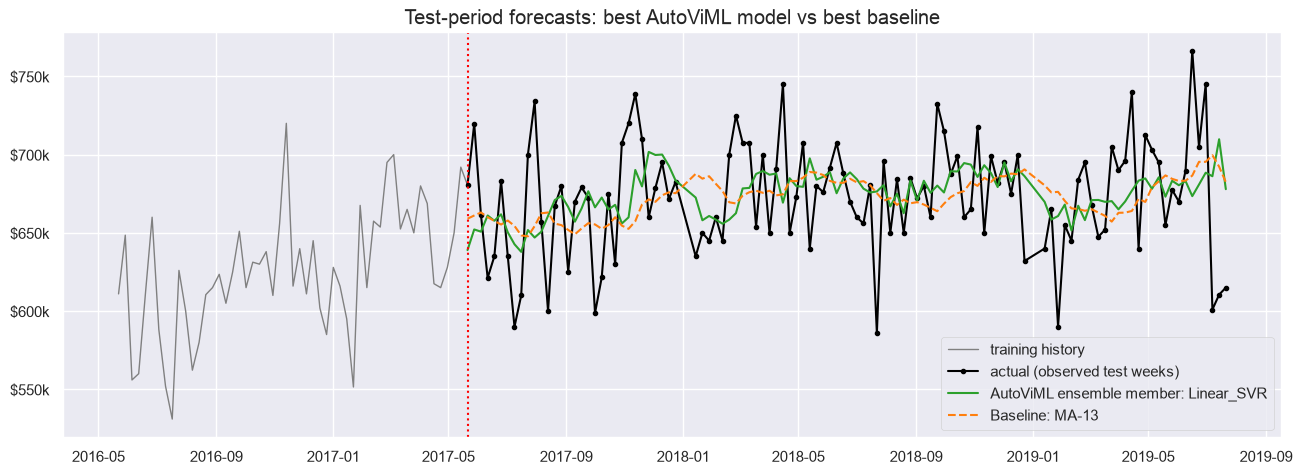

In [33]:
best_avml = res.filter(like="AutoViML", axis=0).index[0]
best_base = res.filter(like="Baseline", axis=0).index[0]
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(weekly["price_clean"].loc[SPLIT_DATE - pd.Timedelta(weeks=52):SPLIT_DATE], color="grey", lw=1, label="training history")
ax.plot(actual, color="black", lw=1.5, marker=".", label="actual (observed test weeks)")
ax.plot(preds[best_avml], color="tab:green", lw=1.5, label=f"{best_avml}")
ax.plot(preds[best_base.replace("Baseline: ", "")], color="tab:orange", lw=1.5, ls="--", label=best_base)
ax.axvline(SPLIT_DATE, color="red", ls=":")
ax.yaxis.set_major_formatter(dollars)
ax.set_title("Test-period forecasts: best AutoViML model vs best baseline")
ax.legend()
plt.show()

Best main AutoViML model: AutoViML CatBoost


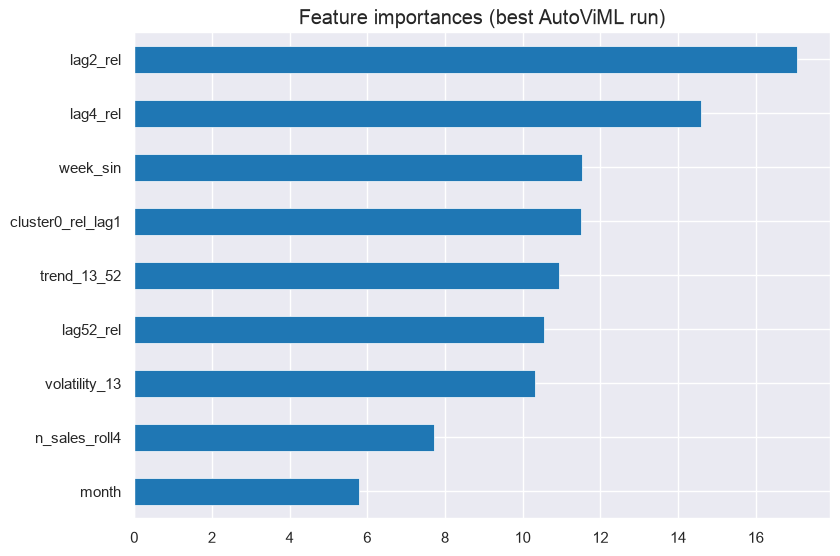

In [34]:
best_main = res[res.index.isin([f"AutoViML {k}" for k in avml_runs])].index[0]   # res is sorted by MAE
best_run = avml_runs[best_main.replace("AutoViML ", "")]
print("Best main AutoViML model:", best_main)
m = best_run["model"]
est = m.steps[-1][1] if hasattr(m, "steps") else m
if hasattr(est, "feature_importances_") and len(est.feature_importances_) == len(best_run["features"]):
    pd.Series(est.feature_importances_, index=best_run["features"]).sort_values().plot.barh(
        figsize=(8, 6), color="tab:blue", title="Feature importances (best AutoViML run)")
    plt.show()
else:
    print("Features kept by AutoViML:", best_run["features"])

## 15. Walk-forward evaluation and significance
Section 14 is **one** split with about 110 noisy test weeks. A $2k MAE difference there could easily be luck. This section asks two harder questions:
1. **Does the result hold across time?** It uses an **expanding-window walk-forward**. For each year from 2013 to 2019, every model is retrained on all weeks *before* 1 January and forecasts that year one week ahead.
2. **Is the gain over MA-13 statistically real?** It uses a **Diebold-Mariano test** on absolute errors (Newey-West variance, because forecast errors are autocorrelated) and a **moving-block bootstrap** 95% confidence interval for the MAE gain. p-values are **Holm-adjusted**, because four AutoViML models are each compared with the baseline.

The early folds overlap the period that sections 9–12 learned from, so to keep every fold clean the walk-forward uses only causally available inputs:
* the causally imputed series **without** the STL anomaly replacement, since that STL fit saw the whole training period;
* **no postcode-cluster features**, since the clusters were defined on 2009–2016;
* **all** engineered features, with AutoViML's own selection inside each fold replacing the importance-based selection from section 12, which was fit on 2009–2017.

In [35]:
from IPython.utils.capture import capture_output
from scipy import stats
from statsmodels.stats.multitest import multipletests

p_wf = impute_series(weekly["median_price"], BEST_IMPUTER)
F_wf = build_features(p_wf, include_clusters=False)
WF_FEATURES = [c for c in F_wf.columns if not c.startswith("_") and c != TARGET]
WF_ORIGINS = list(pd.date_range("2013-01-01", weekly.index.max(), freq="YS"))

folds = []
for i, origin in enumerate(WF_ORIGINS):
    end = WF_ORIGINS[i + 1] if i + 1 < len(WF_ORIGINS) else weekly.index.max() + pd.Timedelta(days=1)
    tr = F_wf[F_wf.index < origin]
    te = F_wf[(F_wf.index >= origin) & (F_wf.index < end)]
    fold = pd.DataFrame({"fold": origin.year, "actual": te["_actual"], "observed": te["_observed"]}, index=te.index)
    fold["Naive (last week)"] = p_wf.shift(1).loc[te.index]
    fold["MA-4"] = p_wf.shift(1).rolling(4).mean().loc[te.index]
    fold["MA-13"] = te["_base"]
    for name, flag in AVML_CONFIGS.items():
        with capture_output():                                    # silence AutoViML's per-run logging
            _, _, _, testm = Auto_ViML(tr[WF_FEATURES + [TARGET]].reset_index(drop=True), TARGET,
                                       te[WF_FEATURES].reset_index(drop=True), sample_submission="",
                                       hyper_param="RS", feature_reduction=True, scoring_parameter="",
                                       Boosting_Flag=flag, KMeans_Featurizer=False, Binning_Flag=False, Add_Poly=0,
                                       Stacking_Flag=False, Imbalanced_Flag=False, verbose=0)
        plt.close("all")
        fold[f"AutoViML {name}"] = te["_base"].values * (1 + testm[f"{TARGET}_predictions"].values)
    folds.append(fold[fold["observed"]])
    print(f"fold {origin.year}: trained on {len(tr)} weeks, scored {int(fold['observed'].sum())} observed weeks")

wf = pd.concat(folds)
WF_MODELS = [c for c in wf.columns if c not in ("fold", "actual", "observed")]
abs_err = wf[WF_MODELS].sub(wf["actual"], axis=0).abs()

fold 2013: trained on 174 weeks, scored 51 observed weeks


fold 2014: trained on 226 weeks, scored 51 observed weeks


fold 2015: trained on 278 weeks, scored 51 observed weeks


fold 2016: trained on 330 weeks, scored 50 observed weeks


fold 2017: trained on 382 weeks, scored 50 observed weeks


fold 2018: trained on 435 weeks, scored 50 observed weeks


fold 2019: trained on 487 weeks, scored 28 observed weeks


fold,2013,2014,2015,2016,2017,2018,2019,all folds
AutoViML RandomForest,"$27,838","$22,252","$27,777","$30,912","$31,157","$24,119","$34,024","$27,895"
AutoViML CatBoost,"$27,941","$21,787","$28,265","$31,030","$32,293","$23,489","$34,828","$28,077"
AutoViML Linear,"$28,509","$22,613","$28,163","$33,386","$34,245","$26,369","$32,268","$29,145"
MA-13,"$28,238","$22,272","$28,595","$33,777","$34,245","$26,369","$35,334","$29,436"
MA-4,"$29,401","$24,176","$30,174","$30,746","$34,536","$25,569","$35,662","$29,645"
AutoViML XGBoost,"$33,754","$30,355","$33,092","$34,741","$40,831","$33,660","$36,045","$34,526"
Naive (last week),"$38,079","$32,762","$36,191","$40,097","$36,056","$33,830","$37,593","$36,285"


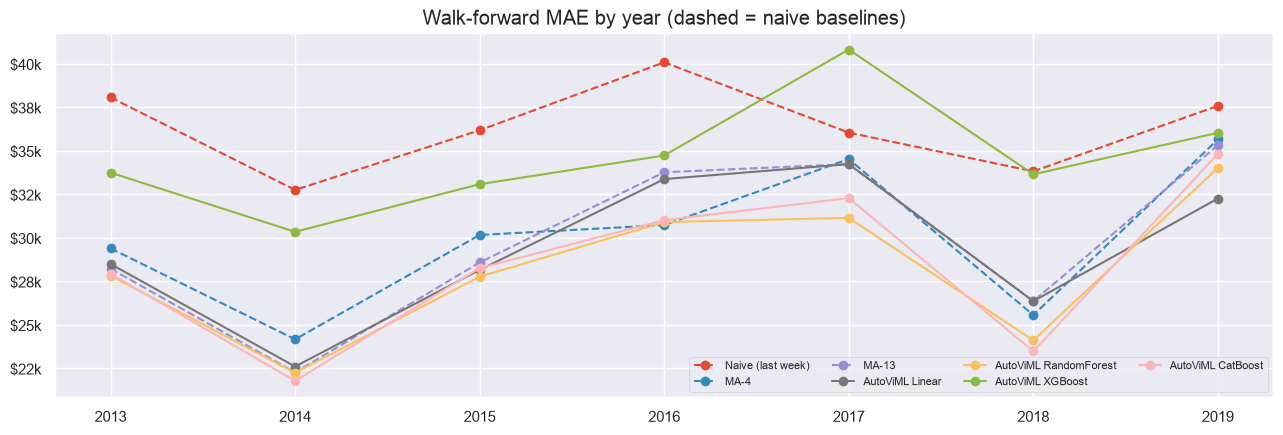

In [36]:
by_fold = abs_err.groupby(wf["fold"]).mean()
by_fold.loc["all folds"] = abs_err.mean()
display(by_fold.T.sort_values("all folds").style.format("${:,.0f}").background_gradient(cmap="Greens_r", axis=0))

fig, ax = plt.subplots(figsize=(14, 4.5))
for mname in WF_MODELS:
    style = "--" if not mname.startswith("AutoViML") else "-"
    ax.plot(by_fold.index[:-1].astype(str), by_fold[mname].iloc[:-1], marker="o", ls=style, label=mname)
ax.yaxis.set_major_formatter(dollars)
ax.set_title("Walk-forward MAE by year (dashed = naive baselines)")
ax.legend(ncol=4, fontsize=8)
plt.show()

In [37]:
def diebold_mariano(err_model, err_bench):
    """DM test on absolute-error loss with Newey-West (HAC) variance. Positive mean = model better than benchmark."""
    d = np.asarray(err_bench) - np.asarray(err_model)
    T, lag = len(d), int(np.floor(len(d) ** (1 / 3)))
    dc = d - d.mean()
    gamma = [dc[k:] @ dc[:T - k] / T for k in range(lag + 1)]
    var = gamma[0] + 2 * sum((1 - k / (lag + 1)) * gamma[k] for k in range(1, lag + 1))
    stat = d.mean() / np.sqrt(var / T)
    return d.mean(), stat, 2 * (1 - stats.norm.cdf(abs(stat)))


def block_bootstrap_ci(d, block=8, reps=2000, seed=RANDOM_STATE):
    rng, d = np.random.default_rng(seed), np.asarray(d)
    T, nb = len(d), int(np.ceil(len(d) / block))
    means = [np.concatenate([d[s:s + block] for s in rng.integers(0, T - block + 1, nb)])[:T].mean() for _ in range(reps)]
    return np.percentile(means, [2.5, 97.5])


rows = []
for mname in [m for m in WF_MODELS if m != "MA-13"]:
    gain, dm, pval = diebold_mariano(abs_err[mname], abs_err["MA-13"])
    lo, hi = block_bootstrap_ci(abs_err["MA-13"].values - abs_err[mname].values)
    rows.append({"model": mname, "walk-forward MAE": abs_err[mname].mean(), "MAE gain vs MA-13": gain,
                 "95% CI (block bootstrap)": f"[{lo:,.0f}, {hi:,.0f}]", "DM statistic": dm, "p-value": pval})
sig = pd.DataFrame(rows).set_index("model").sort_values("walk-forward MAE")
is_avml = sig.index.str.startswith("AutoViML")
sig["p (Holm, AutoViML)"] = np.nan
sig.loc[is_avml, "p (Holm, AutoViML)"] = multipletests(sig.loc[is_avml, "p-value"], method="holm")[1]
sig["better than MA-13 at 5%?"] = np.where(is_avml, sig["p (Holm, AutoViML)"] < 0.05, sig["p-value"] < 0.05) & (sig["MAE gain vs MA-13"] > 0)
print(f"{len(wf)} observed weeks across {wf['fold'].nunique()} walk-forward years | MA-13 MAE ${abs_err['MA-13'].mean():,.0f}")
sig.style.format({"walk-forward MAE": "${:,.0f}", "MAE gain vs MA-13": "${:,.0f}", "DM statistic": "{:.2f}",
                  "p-value": "{:.4f}", "p (Holm, AutoViML)": "{:.4f}"})

331 observed weeks across 7 walk-forward years | MA-13 MAE $29,436


,walk-forward MAE,MAE gain vs MA-13,95% CI (block bootstrap),DM statistic,p-value,"p (Holm, AutoViML)",better than MA-13 at 5%?
model,,,,,,,
AutoViML RandomForest,"$27,895","$1,541","[720, 2,569]",3.39,0.0007,0.0021,True
AutoViML CatBoost,"$28,077","$1,359","[219, 2,658]",2.22,0.0267,0.0533,False
AutoViML Linear,"$29,145",$291,"[-173, 596]",1.18,0.2387,0.2387,False
MA-4,"$29,645",$-209,"[-1,681, 1,147]",-0.28,0.7833,nan,False
AutoViML XGBoost,"$34,526","$-5,090","[-7,733, -2,587]",-3.92,0.0001,0.0004,False
Naive (last week),"$36,285","$-6,849","[-9,906, -4,673]",-5.00,0.0000,nan,False


> ✍️ **Your observations (walk-forward):** is the AutoViML gain over MA-13 consistent across years, or driven by one or two folds? Is it statistically significant after the Holm correction? How does the single-split result in section 14 compare with the walk-forward picture?

## 16. Conclusions
> ✍️ **TODO (you), after running everything:**
> - **Data preparation:** what the raw transactions needed (bedroom imputation, price anomalies, sparse early years, missing weeks), why the anomaly rule must be postcode-aware, why imputation must be causal, and why the weekly series was built the way it was.
> - **Time-series findings:** trend, seasonality, stationarity, postcode clusters.
> - **Models:** did any AutoViML model beat the naive baselines, on the holdout (section 14) *and* in the walk-forward (section 15)? Is the gain statistically significant? If not, explain why: weekly medians are noisy and close to a random walk around the trend, so that is itself a useful finding.
> - **Limitations and next steps:** a mix-adjusted (postcode × bedrooms) price index as the target, monthly frequency, multi-week horizons, classical baselines (ETS/SARIMA), dedicated time-series AutoML (e.g. Auto_TS).